<a href="https://colab.research.google.com/github/pual113-png/TEST1/blob/main/SK_Energy_RT_YOLOv5x%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys, platform, torch

print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("GPU가 잡히지 않았습니다. Colab에서 런타임을 GPU로 변경하세요.")

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA L4


In [ ]:
%cd /content
!rm -rf paper_repo steel_data steel-tube-dataset-all.zip
!git clone -q https://github.com/huangyebiaoke/steel-pipe-weld-defect-detection.git paper_repo

!wget -q --show-progress \
  https://github.com/huangyebiaoke/steel-pipe-weld-defect-detection/releases/download/1.0/steel-tube-dataset-all.zip \
  -O /content/steel-tube-dataset-all.zip

!mkdir -p /content/steel_data
!unzip -q /content/steel-tube-dataset-all.zip -d /content/steel_data

print("다운로드/압축해제 완료")

/content
/content/steel-tube 100%[===================>] 773.00M  9.20MB/s    in 78s     
다운로드/압축해제 완료


In [ ]:
from pathlib import Path

root = Path("/content/steel_data")
img_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

images = [p for p in root.rglob("*") if p.suffix.lower() in img_exts]
txts = list(root.rglob("*.txt"))
yamls = list(root.rglob("*.yaml")) + list(root.rglob("*.yml"))
xmls = list(root.rglob("*.xml"))

print("이미지:", len(images))
print("TXT:", len(txts))
print("XML:", len(xmls))
print("YAML:", len(yamls))

print("\n상위 폴더 구조:")
!find /content/steel_data -maxdepth 3 -type d | head -80

print("\n발견한 YAML:")
for p in yamls[:20]:
    print(p)

이미지: 6816
TXT: 3414
XML: 3408
YAML: 0

상위 폴더 구조:
/content/steel_data
/content/steel_data/steel-tube-dataset-all
/content/steel_data/steel-tube-dataset-all/yolo
/content/steel_data/steel-tube-dataset-all/yolo/images
/content/steel_data/steel-tube-dataset-all/yolo/labels
/content/steel_data/steel-tube-dataset-all/pascal-voc-2007
/content/steel_data/steel-tube-dataset-all/pascal-voc-2007/VOCdevkit

발견한 YAML:


In [ ]:
from PIL import Image
from collections import Counter

modes = Counter()
for p in images[:200]:
    try:
        modes[Image.open(p).mode] += 1
    except Exception:
        pass

print("PIL mode 분포(최대 200장 검사):", modes)

if images:
    p = images[0]
    im = Image.open(p)
    print("예시:", p)
    print("mode:", im.mode, "size:", im.size)

PIL mode 분포(최대 200장 검사): Counter({'RGB': 200})
예시: /content/steel_data/steel-tube-dataset-all/pascal-voc-2007/VOCdevkit/VOC2007/JPEGImages/air-hole7-232.jpg
mode: RGB size: (1182, 816)


In [ ]:
import json
from pathlib import Path

op = Path("/content/paper_repo/steel-tube-dataset-processing-and-analysis/operation.ipynb")
nbj = json.loads(op.read_text(encoding="utf-8"))

keywords = ["augment", "rotate", "gaussian", "noise", "flip", "blur", "hough",
            "grayscale", "gray", "cutout", "crop", "resize", "contrast", "sharp"]

hits = []
for i, cell in enumerate(nbj.get("cells", [])):
    src = "".join(cell.get("source", []))
    if any(k.lower() in src.lower() for k in keywords):
        hits.append((i, cell.get("cell_type"), src[:4000]))

print("관련 셀 수:", len(hits))
for i, ctype, src in hits[:25]:
    print("\n" + "="*80)
    print("CELL", i, ctype)
    print(src)

관련 셀 수: 2

CELL 4 code
import random
from skimage import exposure
import numpy as np
import math
import skimage
from skimage import io
from PIL import Image,ImageEnhance,ImageOps,ImageFile,ImageChops
import copy

def change_light(image,bndboxes):
    # todo:可以加一个步长使明暗变化更明显
    flag=random.uniform(0.4,2.5)
    while(flag==1):
        flag=random.uniform(0.4,2.5)
    image=exposure.adjust_gamma(image,flag)
    for box in bndboxes:
        cv2.rectangle(image,(box['xmin'],box['ymin']),(box['xmax'],box['ymax']),(0,0,255),2)
    return image

def rotate(image,bndboxes,angle=5,scale=1.):
    w=image.shape[1]
    h=image.shape[0]

    rangle=np.deg2rad(angle)
    nw=(abs(np.sin(rangle)*h)+abs(np.cos(rangle)*w))*scale
    nh=(abs(np.cos(rangle)*h)+abs(np.sin(rangle)*w))*scale

    rot_mat=cv2.getRotationMatrix2D((nw*.5,nh*.5),angle,scale)
    rot_move=np.dot(rot_mat,np.array([(nw-w)*.5,(nh-h)*.5,0]))
    rot_mat[0,2]+=rot_move[0]
    rot_mat[1,2]+=rot_move[1]

    rot_img=cv2.warpAffine(image,

In [ ]:
from pathlib import Path
from collections import defaultdict
import math

root = Path("/content/steel_data")
img_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

all_images = [p for p in root.rglob("*") if p.suffix.lower() in img_exts]
all_txts = list(root.rglob("*.txt"))

img_by_stem = defaultdict(list)
for p in all_images:
    img_by_stem[p.stem].append(p)

def parse_yolo_label(path):
    try:
        lines = path.read_text(encoding="utf-8", errors="ignore").strip().splitlines()
    except Exception:
        return None
    if not lines:
        return []
    out = []
    for line in lines:
        parts = line.strip().split()
        if len(parts) != 5:
            return None
        try:
            cls = int(float(parts[0]))
            vals = [float(x) for x in parts[1:]]
        except Exception:
            return None
        if not (0 <= cls <= 7):
            return None
        # YOLO 좌표는 보통 0~1 정규화
        if not all(math.isfinite(v) and -1e-6 <= v <= 1.000001 for v in vals):
            return None
        out.append((cls, *vals))
    return out

pairs = []
for lp in all_txts:
    parsed = parse_yolo_label(lp)
    if parsed is None:
        continue
    candidates = img_by_stem.get(lp.stem, [])
    if not candidates:
        continue

    # labels -> images 경로 대응을 우선 시도
    chosen = None
    lp_str = str(lp)
    for token_a, token_b in [("/labels/", "/images/"), ("\\labels\\", "\\images\\")]:
        guess_base = lp_str.replace(token_a, token_b)
        guess_base = str(Path(guess_base).with_suffix(""))
        for ext in img_exts:
            gp = Path(guess_base + ext)
            if gp.exists():
                chosen = gp
                break
        if chosen:
            break

    if chosen is None:
        # 같은 stem이 하나면 바로 연결
        if len(candidates) == 1:
            chosen = candidates[0]
        else:
            # 경로 공통부분이 가장 긴 후보
            def score(p):
                a = lp.parts
                b = p.parts
                return sum(x == y for x, y in zip(a, b))
            chosen = max(candidates, key=score)

    pairs.append((chosen, lp, parsed))

# 중복 제거
unique = {}
for imgp, labp, parsed in pairs:
    unique[(str(imgp.resolve()), str(labp.resolve()))] = (imgp, labp, parsed)
pairs = list(unique.values())

print("YOLO image-label pair 수:", len(pairs))
print("예시 10개:")
for x in pairs[:10]:
    print(x[0], "<->", x[1], "objects:", len(x[2]))

if len(pairs) == 0:
    raise RuntimeError("YOLO 형식 pair를 찾지 못했습니다. 위 폴더 구조 출력을 확인해야 합니다.")

YOLO image-label pair 수: 3408
예시 10개:
/content/steel_data/steel-tube-dataset-all/yolo/images/val2021/air-hole7-382.jpg <-> /content/steel_data/steel-tube-dataset-all/yolo/labels/val2021/air-hole7-382.txt objects: 4
/content/steel_data/steel-tube-dataset-all/yolo/images/val2021/broken-arc3(air-hole)-213.jpg <-> /content/steel_data/steel-tube-dataset-all/yolo/labels/val2021/broken-arc3(air-hole)-213.txt objects: 1
/content/steel_data/steel-tube-dataset-all/yolo/images/val2021/broken-arc2-150.jpg <-> /content/steel_data/steel-tube-dataset-all/yolo/labels/val2021/broken-arc2-150.txt objects: 1
/content/steel_data/steel-tube-dataset-all/yolo/images/val2021/air-hole3-56.jpg <-> /content/steel_data/steel-tube-dataset-all/yolo/labels/val2021/air-hole3-56.txt objects: 6
/content/steel_data/steel-tube-dataset-all/yolo/images/val2021/air-hole14-087.jpg <-> /content/steel_data/steel-tube-dataset-all/yolo/labels/val2021/air-hole14-087.txt objects: 2
/content/steel_data/steel-tube-dataset-all/yolo/i

In [ ]:
from collections import Counter

class_names = [
    "air-hole",
    "bite-edge",
    "broken-arc",
    "crack",
    "hollow-bead",
    "overlap",
    "slag-inclusion",
    "unfused",
]

obj_counts = Counter()
empty_labels = 0
for _, _, parsed in pairs:
    if not parsed:
        empty_labels += 1
    for row in parsed:
        obj_counts[row[0]] += 1

print("pair images:", len(pairs))
print("empty label images:", empty_labels)
print("\nobject counts:")
for i, name in enumerate(class_names):
    print(i, name, obj_counts[i])

pair images: 3408
empty label images: 8

object counts:
0 air-hole 5191
1 bite-edge 35
2 broken-arc 458
3 crack 119
4 hollow-bead 229
5 overlap 223
6 slag-inclusion 120
7 unfused 408


In [ ]:
import random, shutil, hashlib, yaml
from pathlib import Path
from collections import Counter

random.seed(42)

pairs_shuffled = pairs.copy()
random.shuffle(pairs_shuffled)

n = len(pairs_shuffled)
cut = int(n * 0.8)
train_pairs = pairs_shuffled[:cut]
val_pairs = pairs_shuffled[cut:]

out = Path("/content/weld_yolo")
if out.exists():
    shutil.rmtree(out)

for split in ["train", "val"]:
    (out / "images" / split).mkdir(parents=True, exist_ok=True)
    (out / "labels" / split).mkdir(parents=True, exist_ok=True)

def safe_name(imgp, labp):
    key = (str(imgp.resolve()) + "|" + str(labp.resolve())).encode()
    h = hashlib.md5(key).hexdigest()[:8]
    return f"{imgp.stem}_{h}"

def copy_pairs(items, split):
    manifest = []
    for imgp, labp, parsed in items:
        base = safe_name(imgp, labp)
        dst_img = out / "images" / split / f"{base}{imgp.suffix.lower()}"
        dst_lab = out / "labels" / split / f"{base}.txt"
        shutil.copy2(imgp, dst_img)
        shutil.copy2(labp, dst_lab)
        manifest.append((dst_img, dst_lab, parsed))
    return manifest

train_manifest = copy_pairs(train_pairs, "train")
val_manifest = copy_pairs(val_pairs, "val")

data_yaml = {
    "path": str(out),
    "train": "images/train",
    "val": "images/val",
    "names": {i: n for i, n in enumerate(class_names)},
}

with open(out / "data.yaml", "w", encoding="utf-8") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False, allow_unicode=True)

print("train images:", len(train_manifest))
print("val images:", len(val_manifest))
print("yaml:", out / "data.yaml")
print((out / "data.yaml").read_text())

train images: 2726
val images: 682
yaml: /content/weld_yolo/data.yaml
path: /content/weld_yolo
train: images/train
val: images/val
names:
  0: air-hole
  1: bite-edge
  2: broken-arc
  3: crack
  4: hollow-bead
  5: overlap
  6: slag-inclusion
  7: unfused



In [ ]:
from collections import Counter

def count_split(manifest):
    c = Counter()
    for _, _, parsed in manifest:
        for row in parsed:
            c[row[0]] += 1
    return c

trc = count_split(train_manifest)
vac = count_split(val_manifest)

print(f"{'class':18s} {'train objects':>14s} {'val objects':>12s}")
for i, name in enumerate(class_names):
    print(f"{name:18s} {trc[i]:14d} {vac[i]:12d}")

missing_val = [class_names[i] for i in range(8) if vac[i] == 0]
if missing_val:
    print("\n주의: val에 없는 class:", missing_val)
    print("seed를 바꿔 다시 split하는 것이 좋습니다.")
else:
    print("\nOK: val에 8개 class가 모두 존재합니다.")

class               train objects  val objects
air-hole                     4156         1035
bite-edge                      27            8
broken-arc                    370           88
crack                          97           22
hollow-bead                   179           50
overlap                       185           38
slag-inclusion                 95           25
unfused                       336           72

OK: val에 8개 class가 모두 존재합니다.


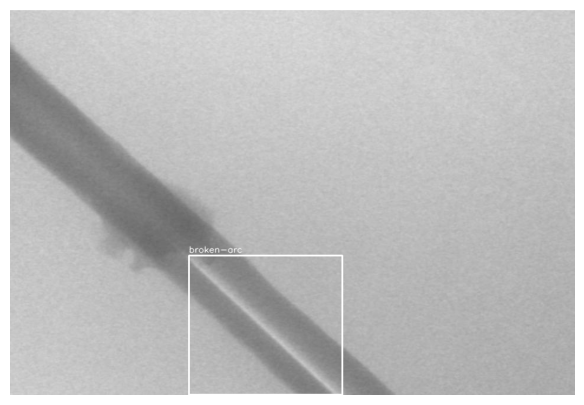

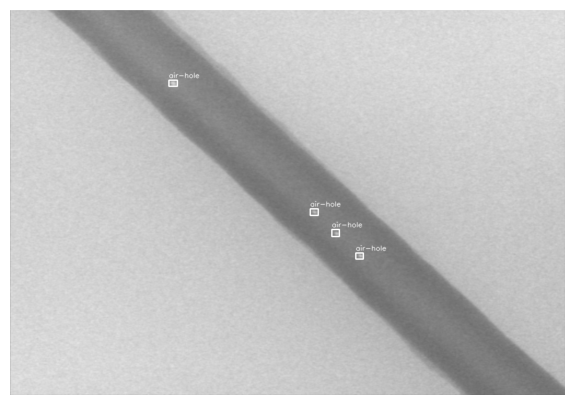

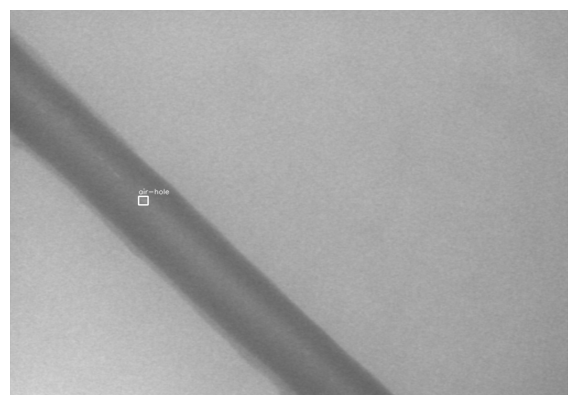

In [ ]:
import cv2, random
import matplotlib.pyplot as plt
from pathlib import Path

def show_labeled(img_path, label_path):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    lines = Path(label_path).read_text().strip().splitlines()
    for line in lines:
        if not line.strip():
            continue
        cls, xc, yc, bw, bh = map(float, line.split())
        cls = int(cls)
        x1 = int((xc - bw/2) * w)
        y1 = int((yc - bh/2) * h)
        x2 = int((xc + bw/2) * w)
        y2 = int((yc + bh/2) * h)
        cv2.rectangle(img, (x1,y1), (x2,y2), (255,255,255), 2)
        cv2.putText(img, class_names[cls], (x1, max(15,y1-5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1, cv2.LINE_AA)

    plt.figure(figsize=(12, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

for imgp, labp, _ in random.sample(train_manifest, min(3, len(train_manifest))):
    show_labeled(imgp, labp)

In [ ]:
%cd /content
!rm -rf yolov5_current
!git clone -q https://github.com/ultralytics/yolov5.git yolov5_current
%cd /content/yolov5_current
!pip install -q -r requirements.txt

import torch
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

/content
/content/yolov5_current
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 11.9 MB/s eta 0:00:00
PyTorch: 2.11.0+cu130
GPU: NVIDIA L4


In [ ]:
%cd /content/yolov5_current

!python train.py \
  --imgsz 640 \
  --batch-size -1 \
  --epochs 10 \
  --data /content/weld_yolo/data.yaml \
  --weights yolov5x.pt \
  --optimizer Adam \
  --project /content/runs_weld \
  --name v5x_smoke10 \
  --exist-ok

/content/yolov5_current
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5x.pt, cfg=, data=/content/weld_yolo/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=10, batch_size=-1, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=N

생성 파일:
F1_curve.png
PR_curve.png
P_curve.png
R_curve.png
confusion_matrix.png
events.out.tfevents.1791001582.471d222f92eb.4119.0
hyp.yaml
labels.jpg
labels_correlogram.jpg
opt.yaml
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights


,epoch,train/box_loss,train/obj_loss,train/cls_loss,metrics/precision,metrics/recall,metrics/mAP_0.5,metrics/mAP_0.5:0.95,val/box_loss,val/obj_loss,val/cls_loss,x/lr0,x/lr1,x/lr2
5,5,0.070952,0.014001,0.023073,0.29323,0.11647,0.15820,0.054968,nan,nan,nan,0.00604,0.00604,0.00604
6,6,0.071190,0.013584,0.020917,0.80045,0.23861,0.25510,0.089575,0.065635,0.012169,0.027367,0.00505,0.00505,0.00505
7,7,0.064202,0.013334,0.016211,0.63686,0.51314,0.58499,0.241850,0.05302,0.010072,0.012456,0.00406,0.00406,0.00406
8,8,0.062087,0.012960,0.014504,0.58737,0.65517,0.64464,0.300750,0.045337,0.0089401,0.010125,0.00307,0.00307,0.00307
9,9,0.059724,0.012138,0.011968,0.60917,0.68505,0.72546,0.315210,0.043822,0.009143,0.0078384,0.00208,0.00208,0.00208


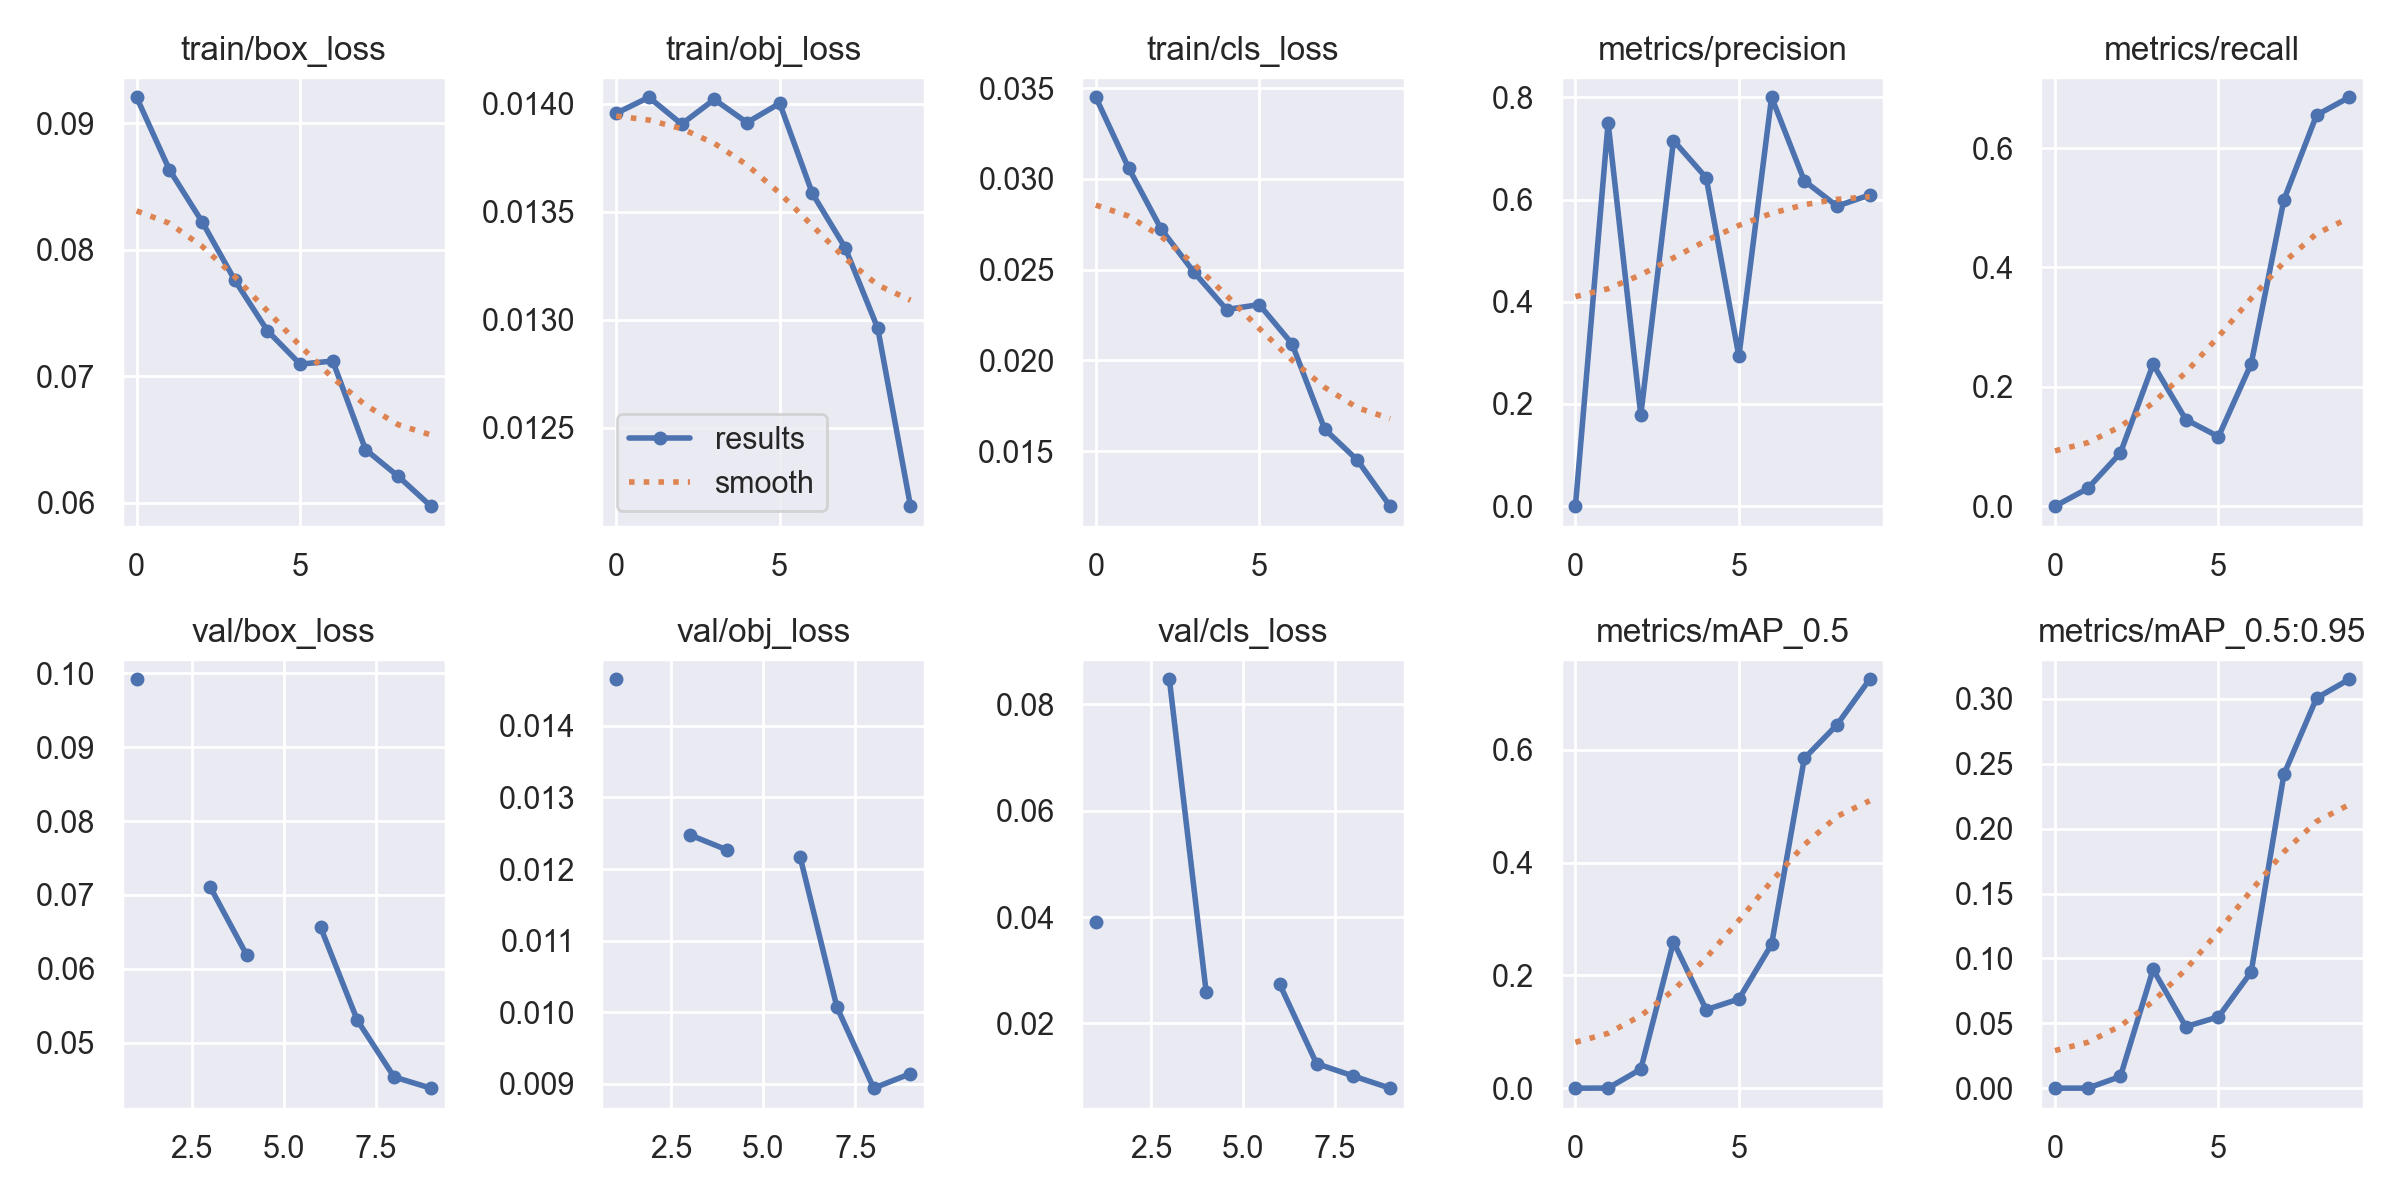

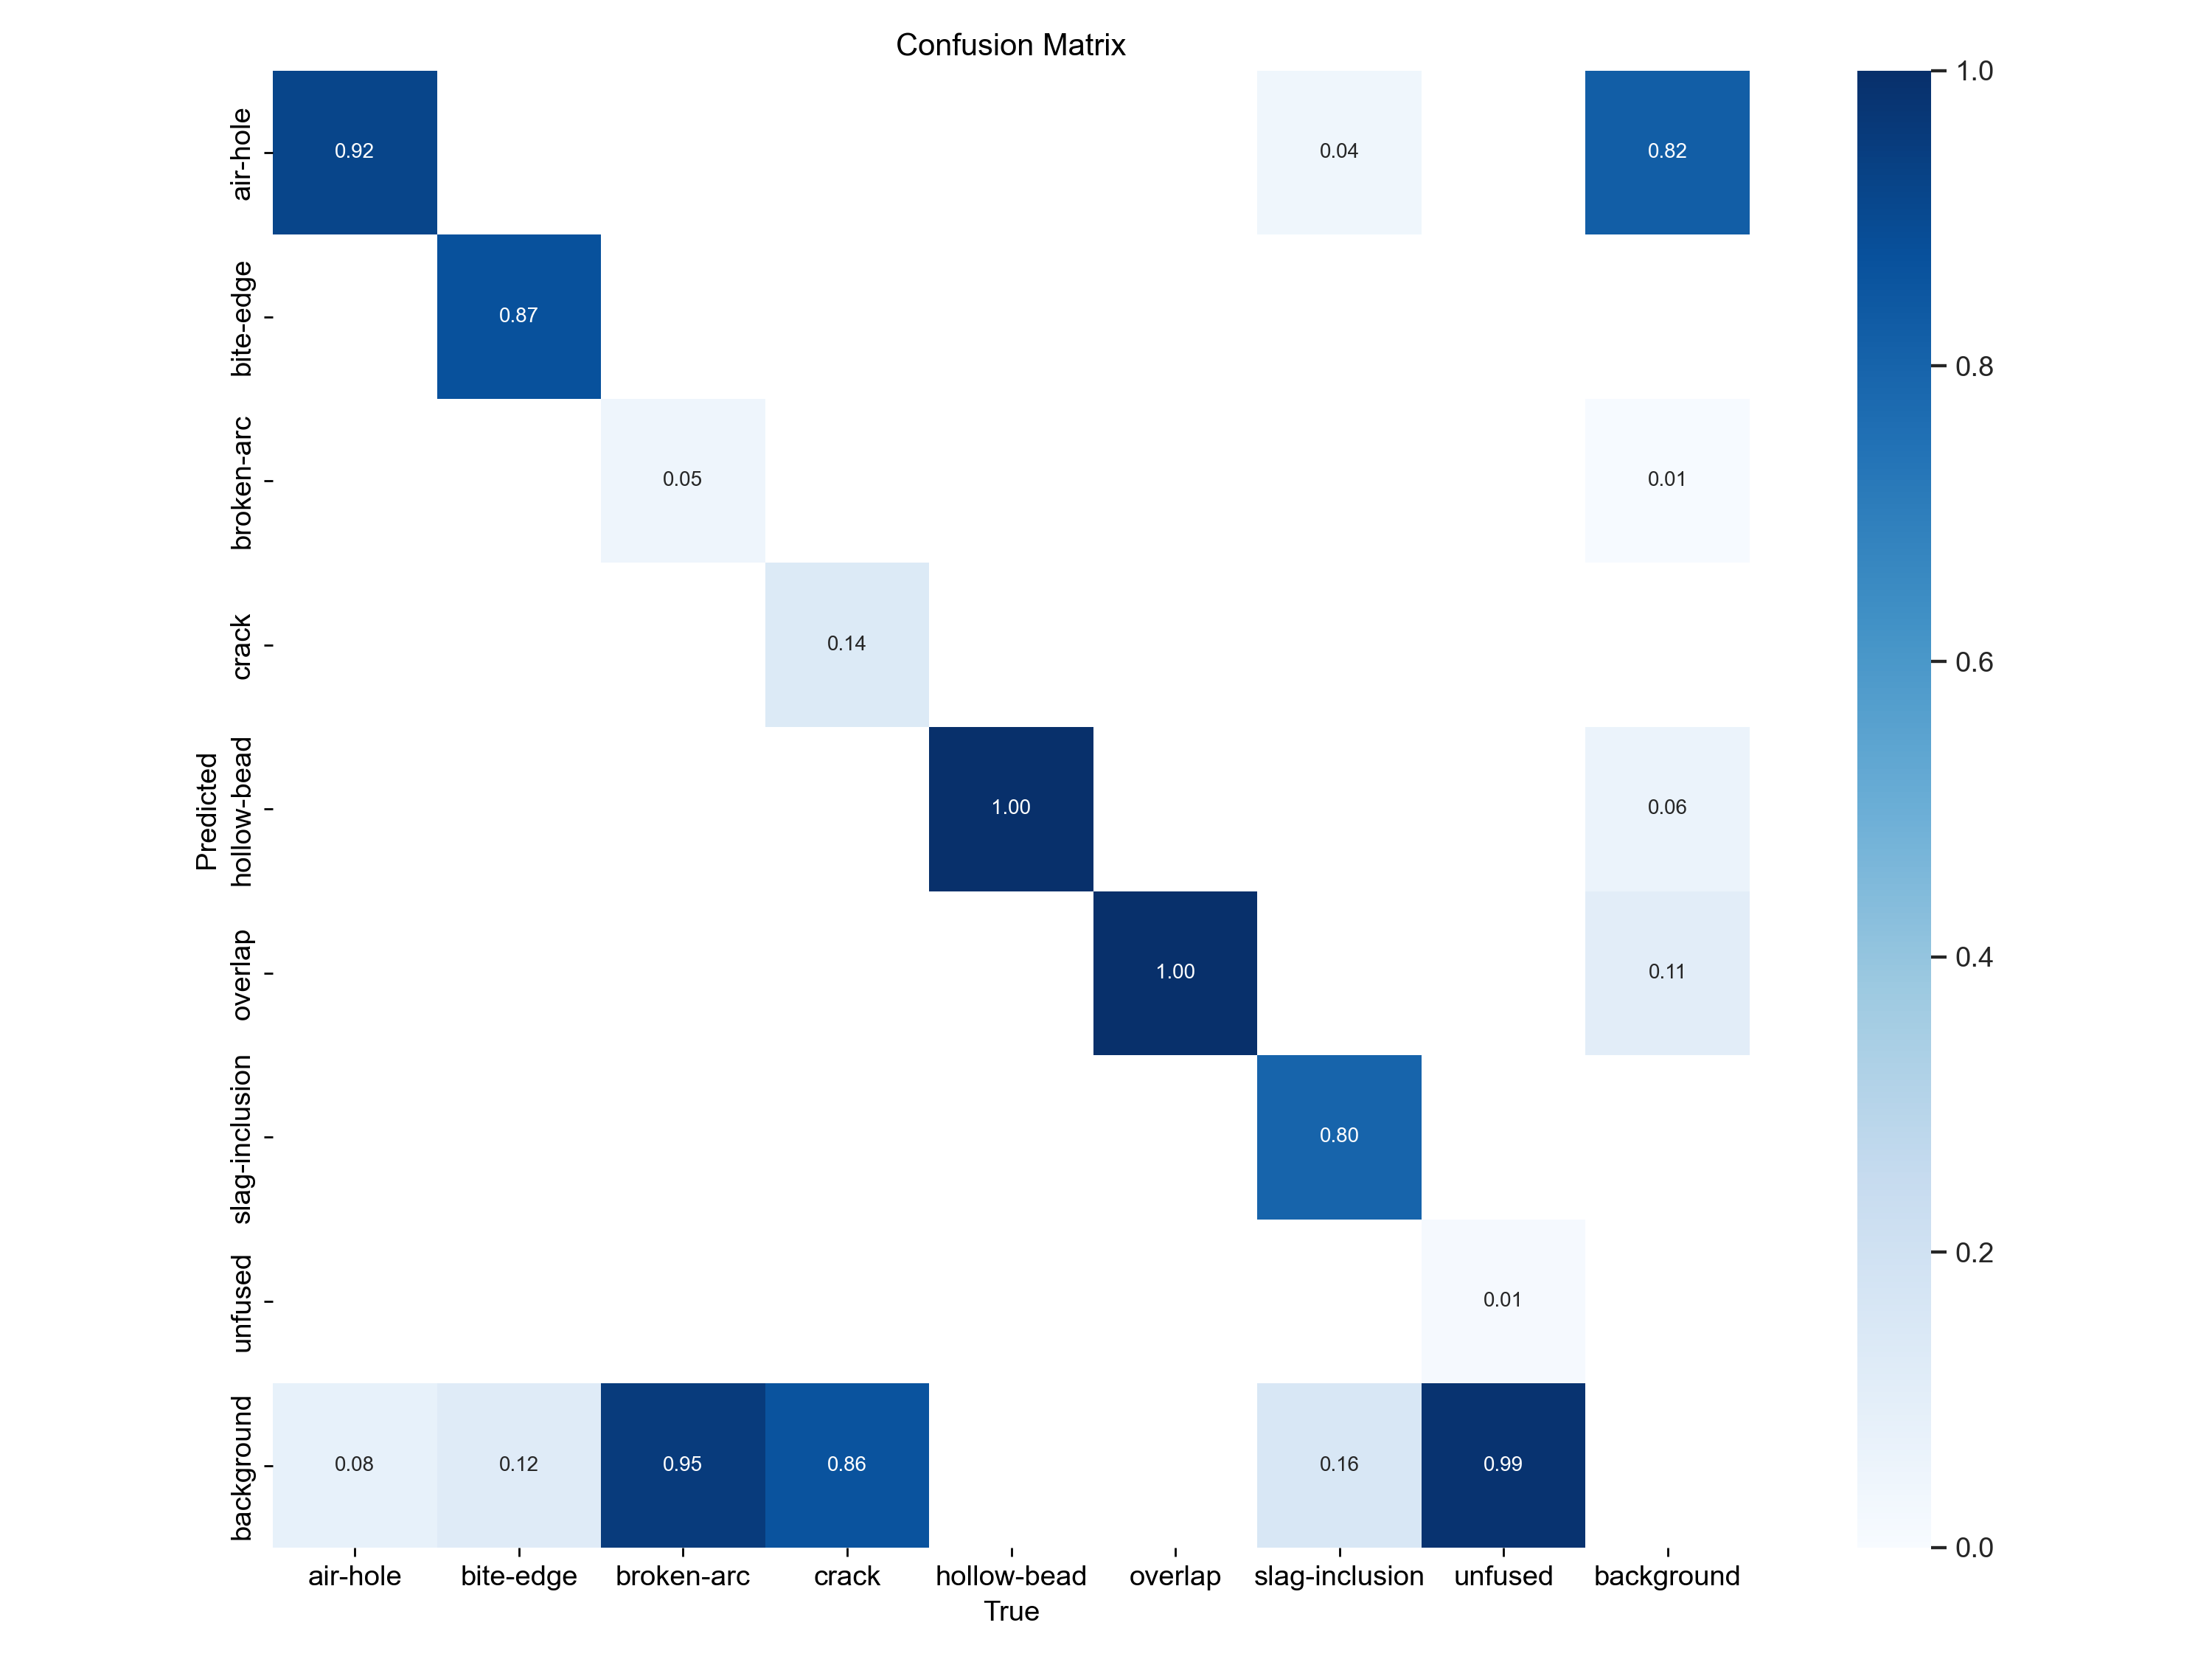

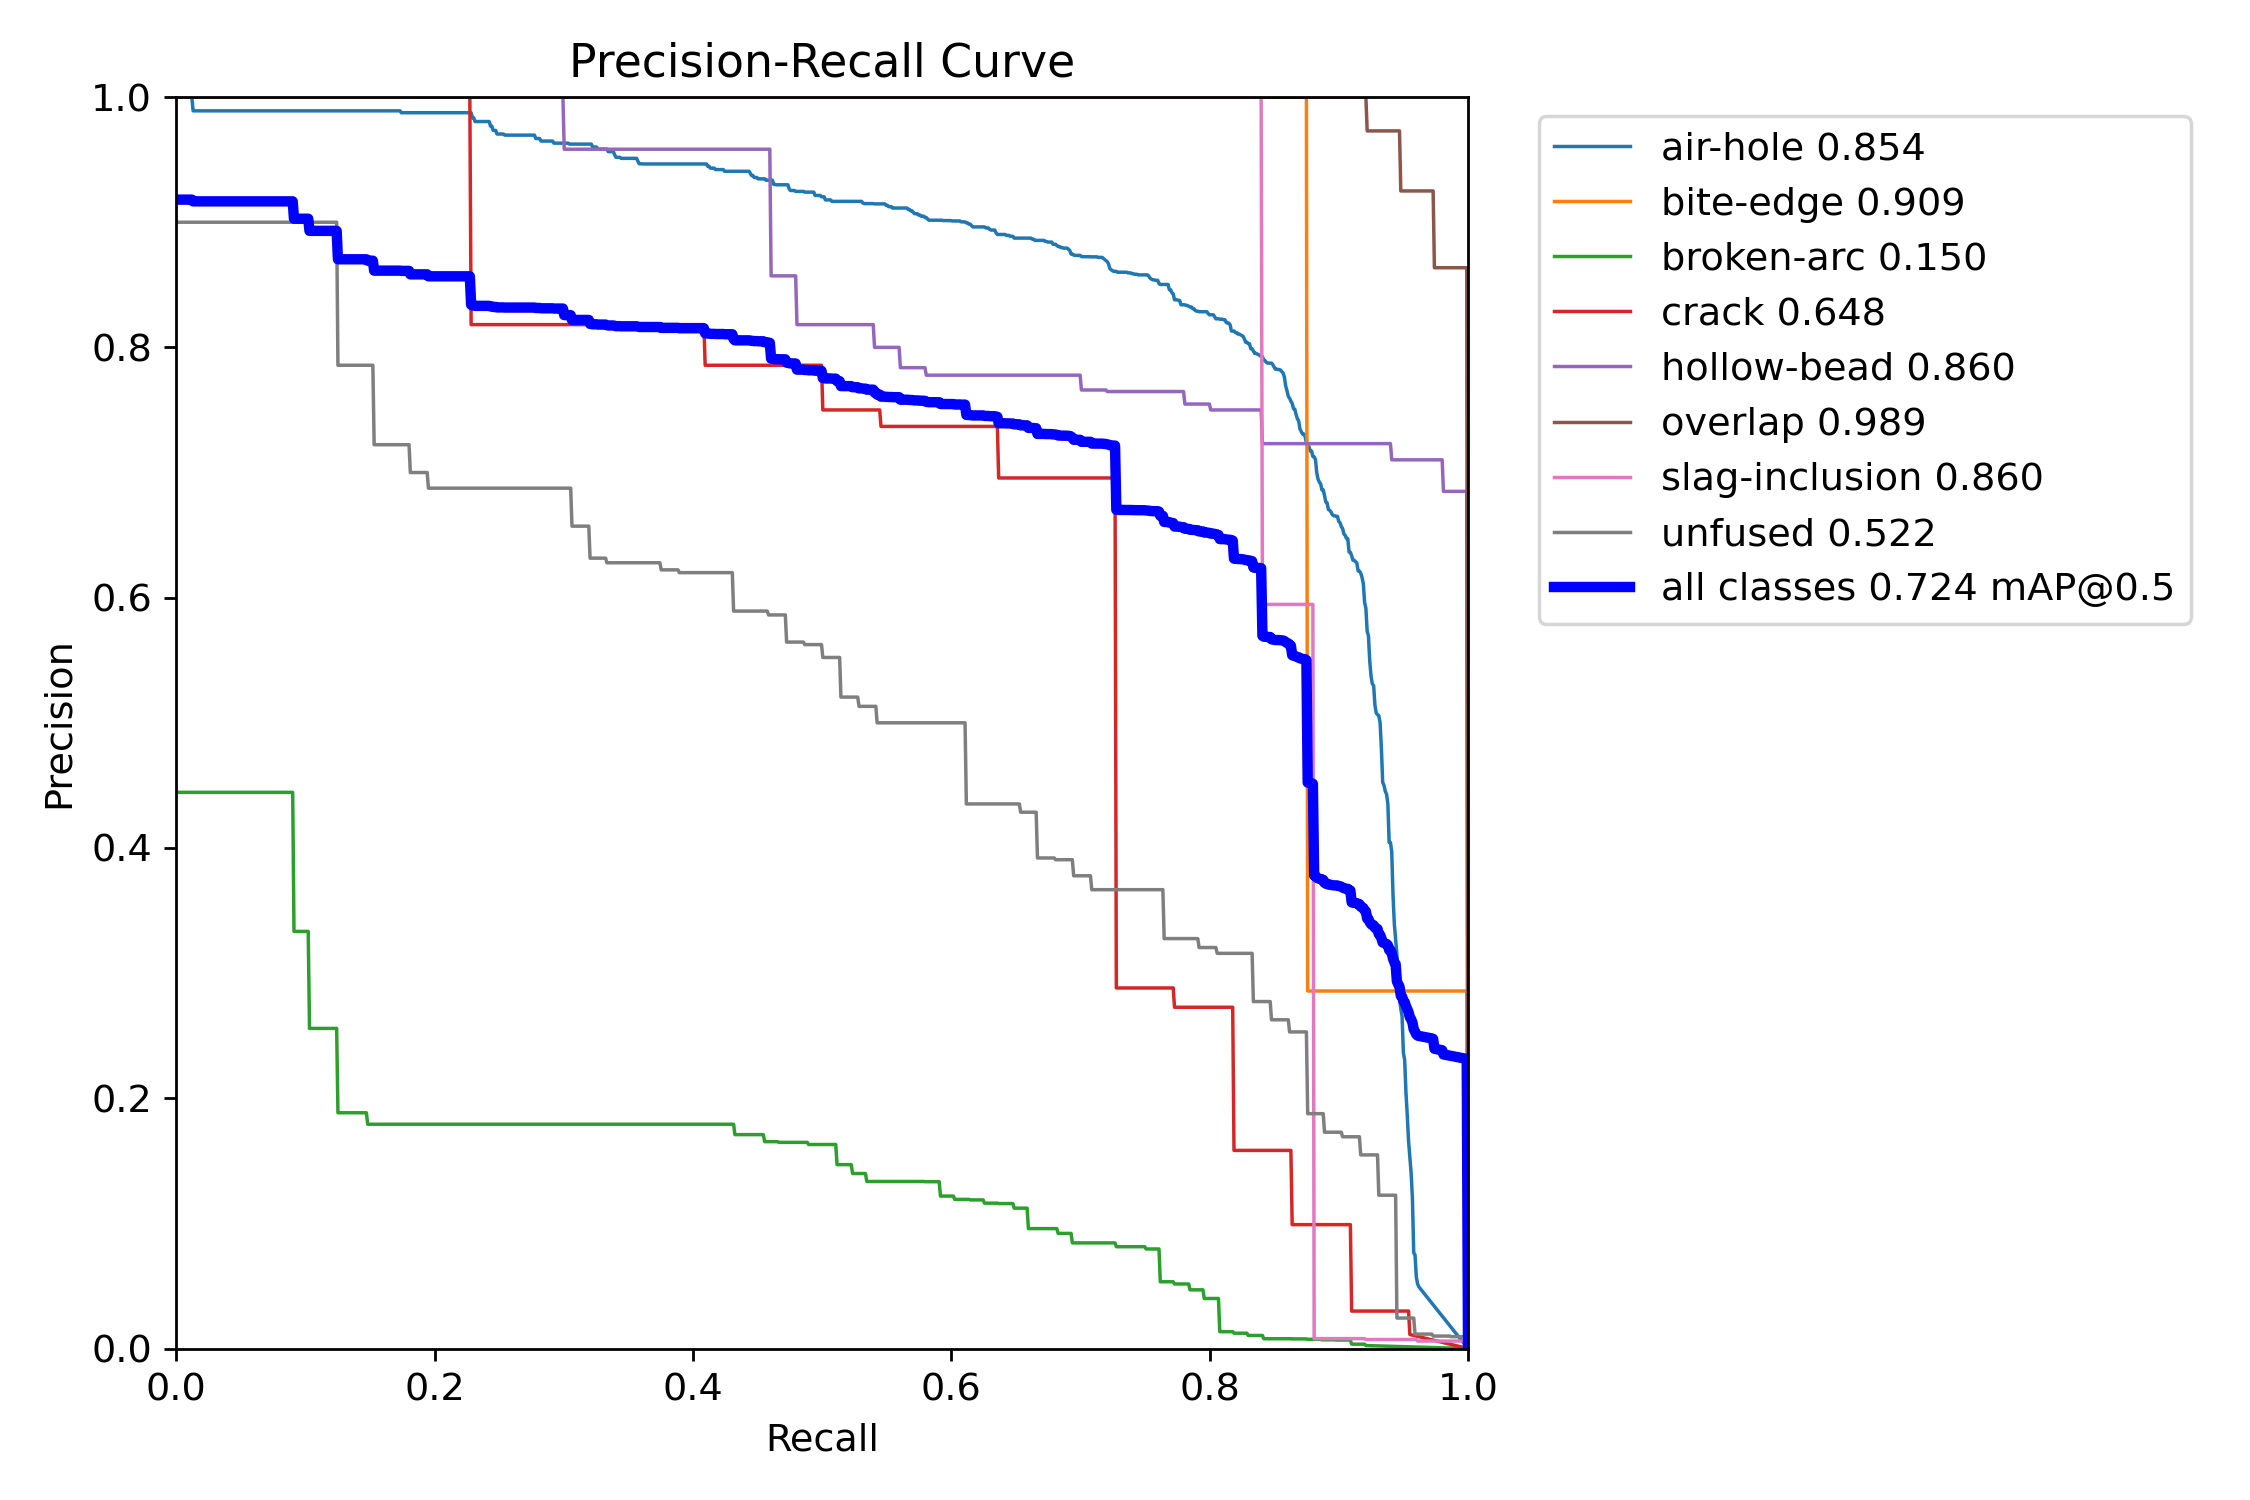

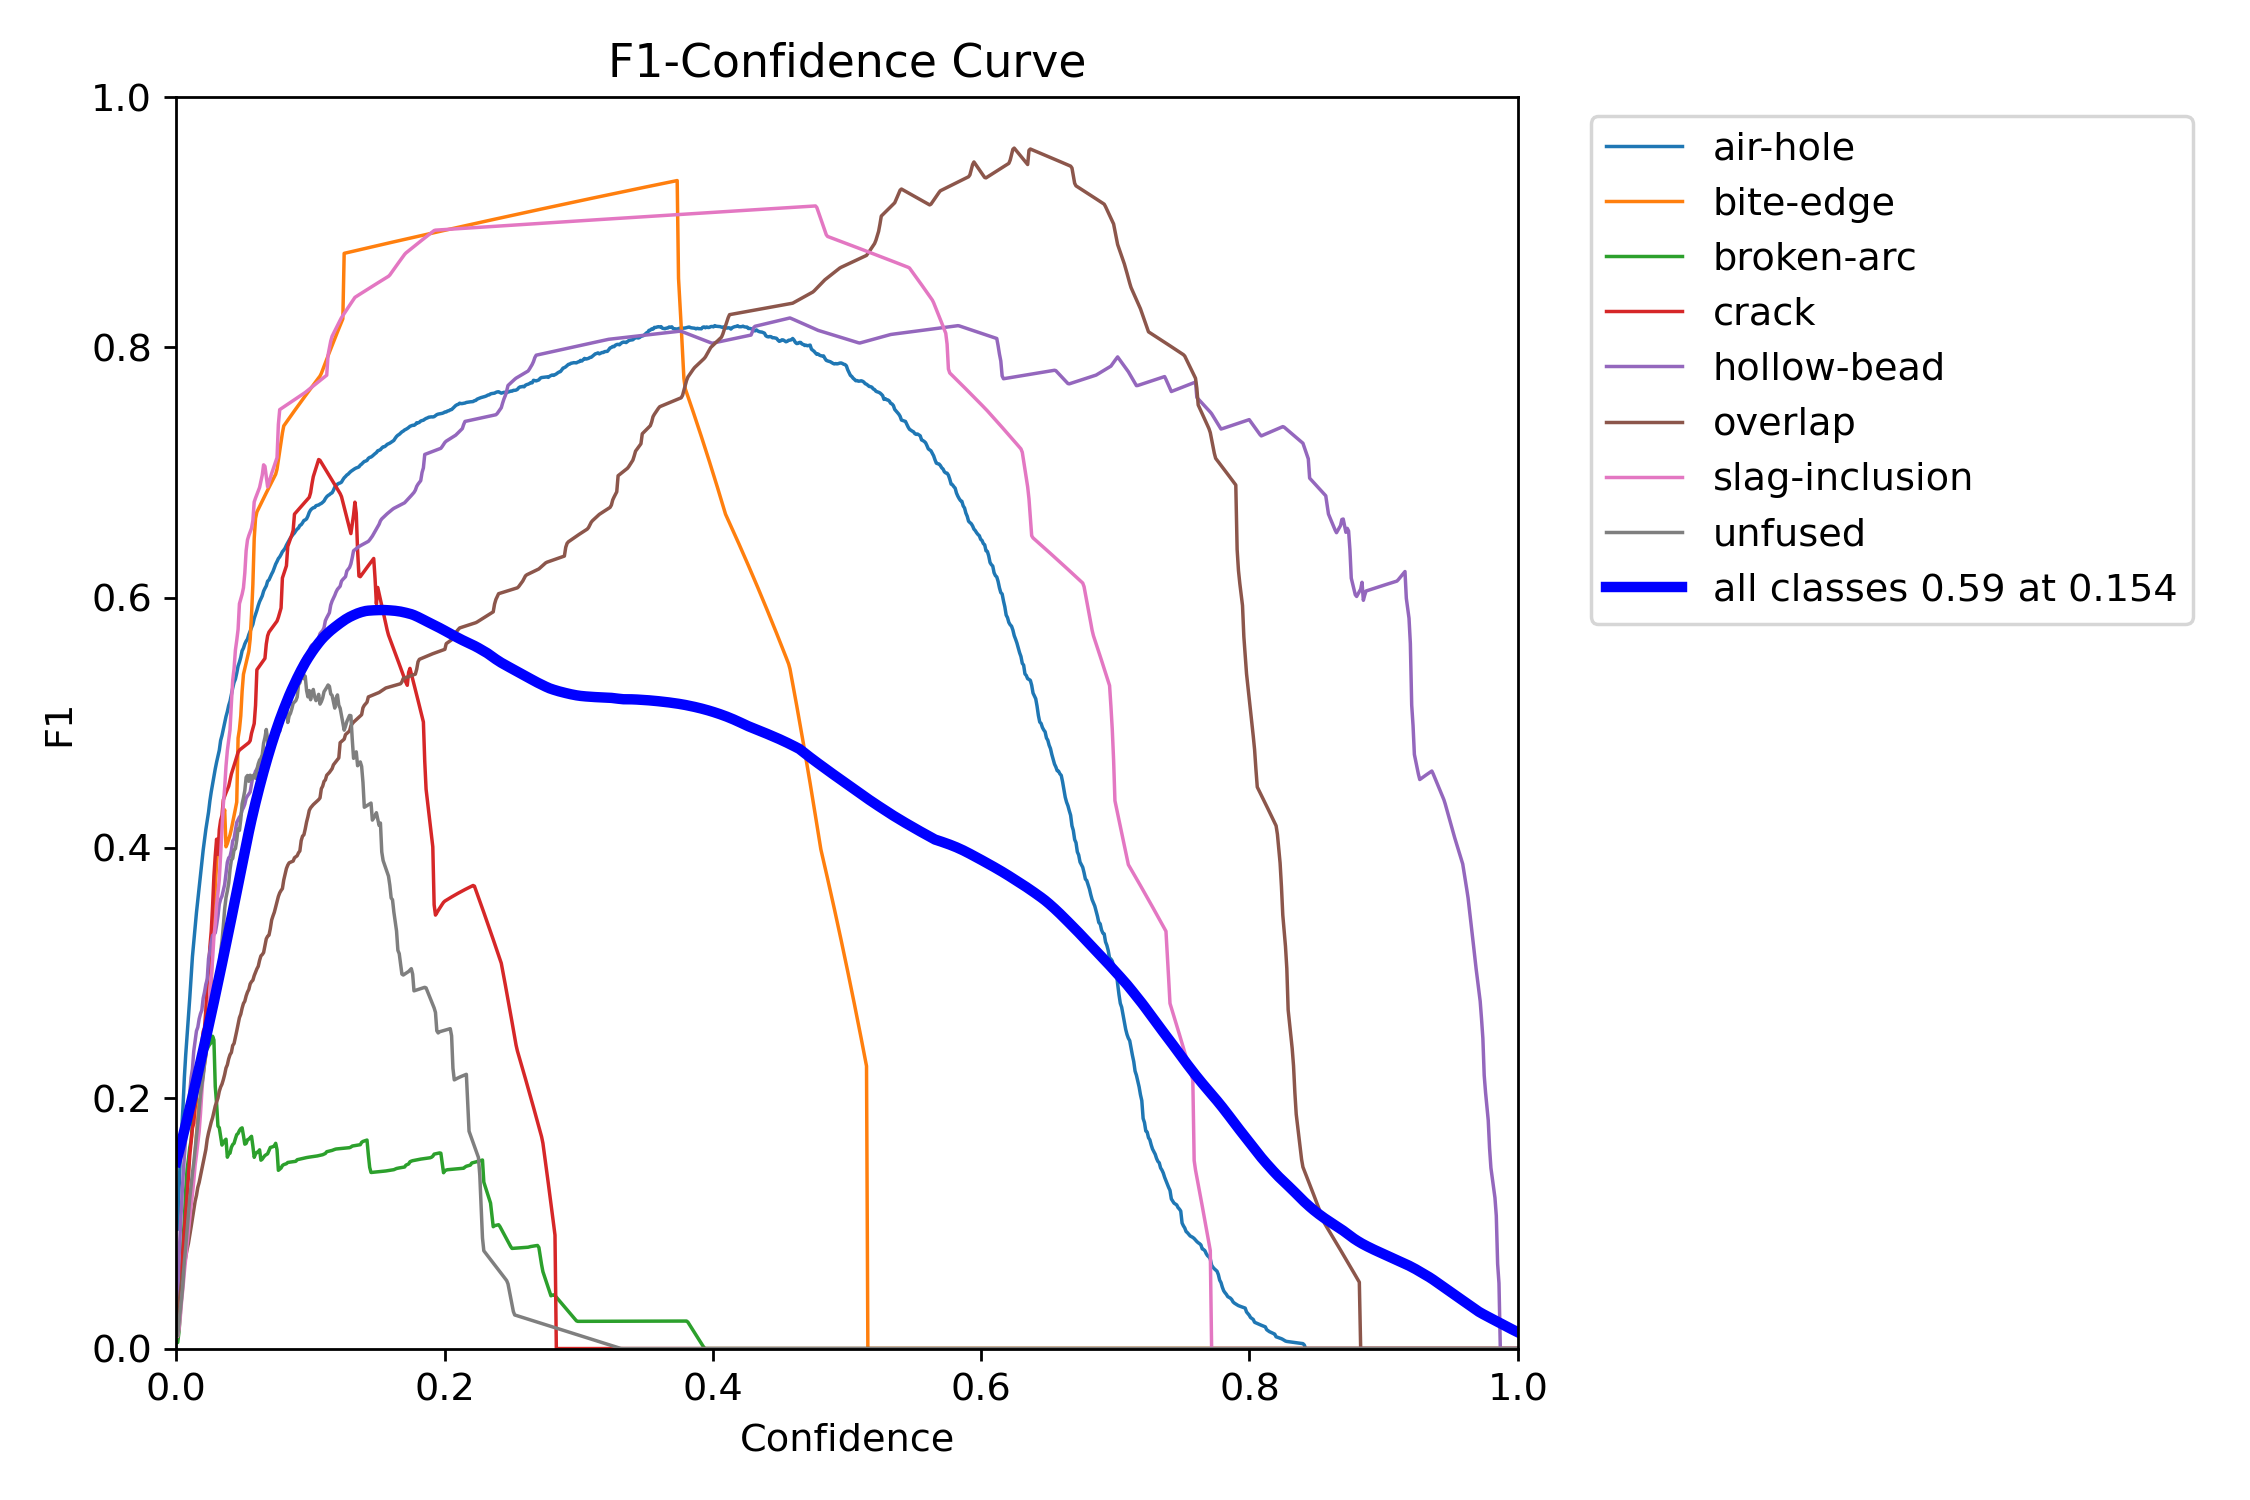

In [ ]:
from pathlib import Path
from IPython.display import display, Image as IPImage
import pandas as pd

run = Path("/content/runs_weld/v5x_smoke10")
print("생성 파일:")
for p in sorted(run.iterdir()):
    print(p.name)

csv_path = run / "results.csv"
if csv_path.exists():
    df = pd.read_csv(csv_path)
    display(df.tail())

for name in ["results.png", "confusion_matrix.png", "PR_curve.png", "F1_curve.png"]:
    p = run / name
    if p.exists():
        display(IPImage(filename=str(p)))

In [ ]:
%cd /content/yolov5_current

!python train.py \
  --imgsz 640 \
  --batch-size -1 \
  --epochs 300 \
  --data /content/weld_yolo/data.yaml \
  --weights yolov5x.pt \
  --optimizer Adam \
  --project /content/drive/MyDrive/RT_weld_project/runs_weld \
  --name v5x_300 \
  --exist-ok \
  --save-period 10

/content/yolov5_current
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5x.pt, cfg=, data=/content/weld_yolo/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=300, batch_size=-1, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print("체크포인트:", os.path.exists(
    "/content/drive/MyDrive/RT_weld_project/runs_weld/v5x_300/weights/last.pt"
))

print("YOLO 코드:", os.path.exists(
    "/content/yolov5_current"
))

print("데이터셋:", os.path.exists(
    "/content/weld_yolo/data.yaml"
))

체크포인트: True
YOLO 코드: False
데이터셋: False


In [ ]:
import os

print(os.path.exists(
    "/content/drive/MyDrive/RT_weld_project/weld_yolo/data.yaml"
))

False


In [ ]:
!mkdir -p /content/drive/MyDrive/RT_weld_project
!rm -rf /content/drive/MyDrive/RT_weld_project/weld_yolo
!cp -r /content/weld_yolo /content/drive/MyDrive/RT_weld_project/

print("데이터셋 Drive 백업 완료")

데이터셋 Drive 백업 완료


In [ ]:
%cd /content/yolov5_current

!python train.py \
  --resume /content/drive/MyDrive/RT_weld_project/runs_weld/v5x_300/weights/last.pt

/content/yolov5_current
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=data/coco128.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=100, batch_size=16, imgsz=640, rect=False, resume=/content/drive/MyDrive/RT_weld_project/runs_weld/v5x_300/weights/last.pt, nosave=False,

In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/RT_weld_project/runs_weld/v5x_300/results.csv"

df = pd.read_csv(path)
df.columns = df.columns.str.strip()

print("총 학습 epoch 수:", len(df))

print("\n=== 마지막 epoch 결과 ===")
print(df.tail(1).to_string(index=False))

# mAP@0.5가 가장 높았던 epoch
best50_idx = df["metrics/mAP_0.5"].idxmax()
print("\n=== mAP@0.5 최고 epoch ===")
print(df.loc[best50_idx].to_string())

# mAP@0.5:0.95가 가장 높았던 epoch
best5095_idx = df["metrics/mAP_0.5:0.95"].idxmax()
print("\n=== mAP@0.5:0.95 최고 epoch ===")
print(df.loc[best5095_idx].to_string())

총 학습 epoch 수: 300

=== 마지막 epoch 결과 ===
 epoch  train/box_loss  train/obj_loss  train/cls_loss  metrics/precision  metrics/recall  metrics/mAP_0.5  metrics/mAP_0.5:0.95         val/box_loss         val/obj_loss         val/cls_loss    x/lr0    x/lr1    x/lr2
   299        0.029724        0.008372        0.000766            0.92422         0.96245          0.96511               0.66793             0.024116            0.0061934           0.00081286 0.000166 0.000166 0.000166

=== mAP@0.5 최고 epoch ===
epoch                                    287
train/box_loss                      0.031026
train/obj_loss                      0.008312
train/cls_loss                      0.001064
metrics/precision                    0.92205
metrics/recall                        0.9658
metrics/mAP_0.5                      0.96608
metrics/mAP_0.5:0.95                 0.66614
val/box_loss                        0.024233
val/obj_loss                       0.0062216
val/cls_loss                      0.00081436
x

In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/RT_weld_project/runs_weld/v5x_300/results.csv"

df = pd.read_csv(path)
df.columns = df.columns.str.strip()

cols = [
    "epoch",
    "metrics/precision",
    "metrics/recall",
    "metrics/mAP_0.5",
    "metrics/mAP_0.5:0.95"
]

for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("=== mAP@0.5 상위 10개 ===")
print(
    df.nlargest(10, "metrics/mAP_0.5")[cols]
    .to_string(index=False)
)

print("\n=== mAP@0.5:0.95 상위 10개 ===")
print(
    df.nlargest(10, "metrics/mAP_0.5:0.95")[cols]
    .to_string(index=False)
)

=== mAP@0.5 상위 10개 ===
 epoch  metrics/precision  metrics/recall  metrics/mAP_0.5  metrics/mAP_0.5:0.95
   287            0.92205         0.96580          0.96608               0.66614
   288            0.92167         0.96411          0.96597               0.66759
   286            0.92085         0.96508          0.96596               0.66675
   285            0.91990         0.96477          0.96565               0.66583
   283            0.91801         0.96774          0.96562               0.66517
   284            0.91898         0.96744          0.96555               0.66466
   279            0.91644         0.96877          0.96541               0.66288
   281            0.91738         0.96838          0.96537               0.66525
   295            0.91850         0.96349          0.96534               0.66633
   296            0.91845         0.96407          0.96528               0.66623

=== mAP@0.5:0.95 상위 10개 ===
 epoch  metrics/precision  metrics/recall  metrics/mAP_0.

results.png


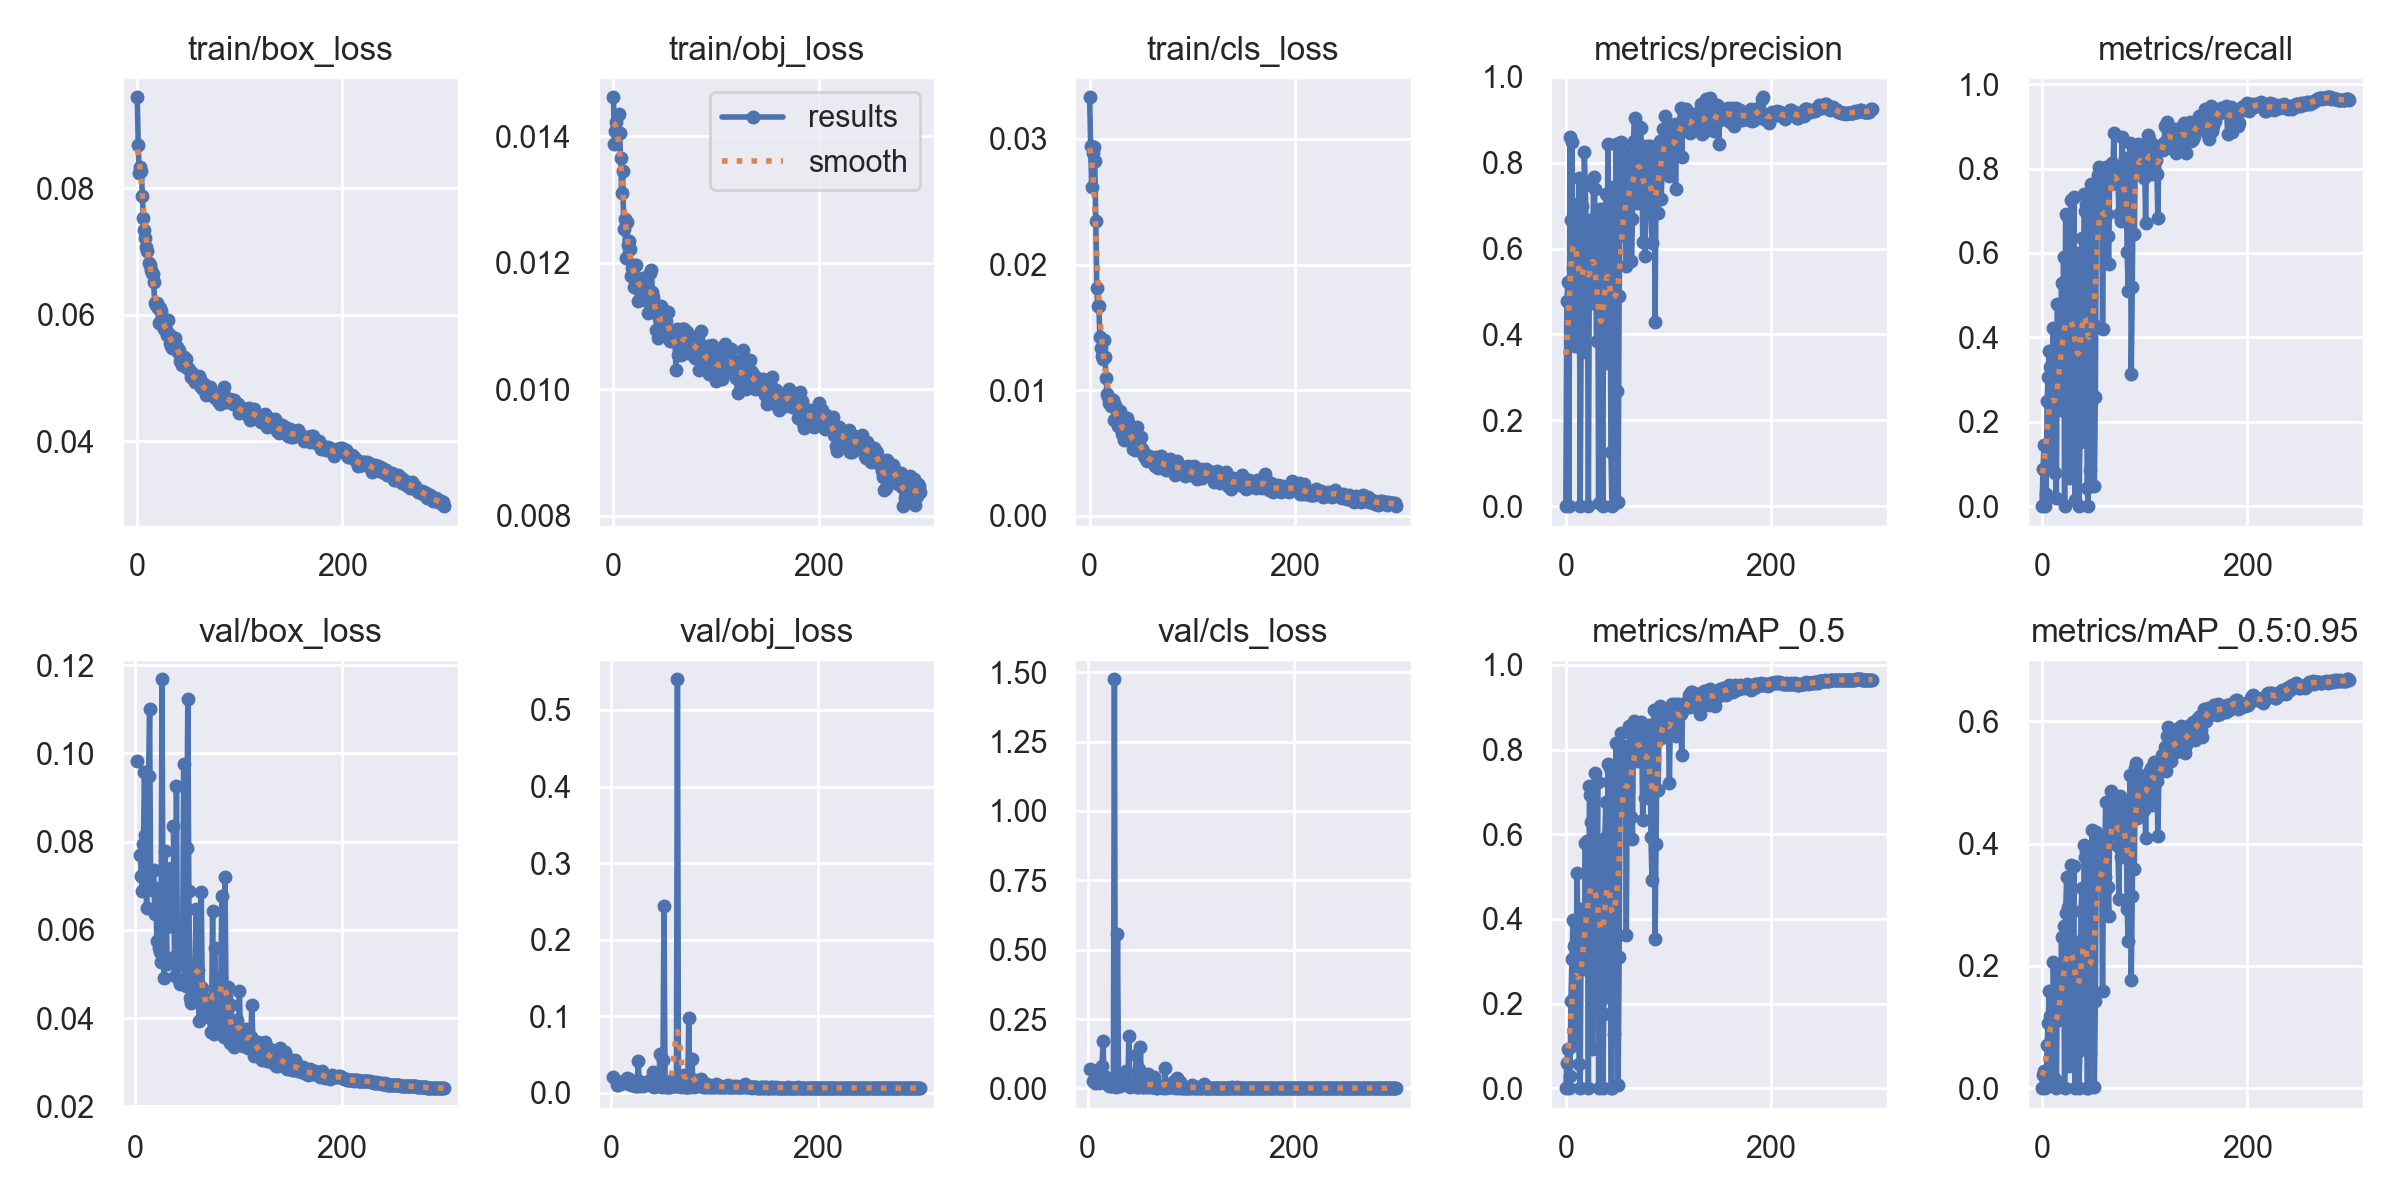

confusion_matrix.png


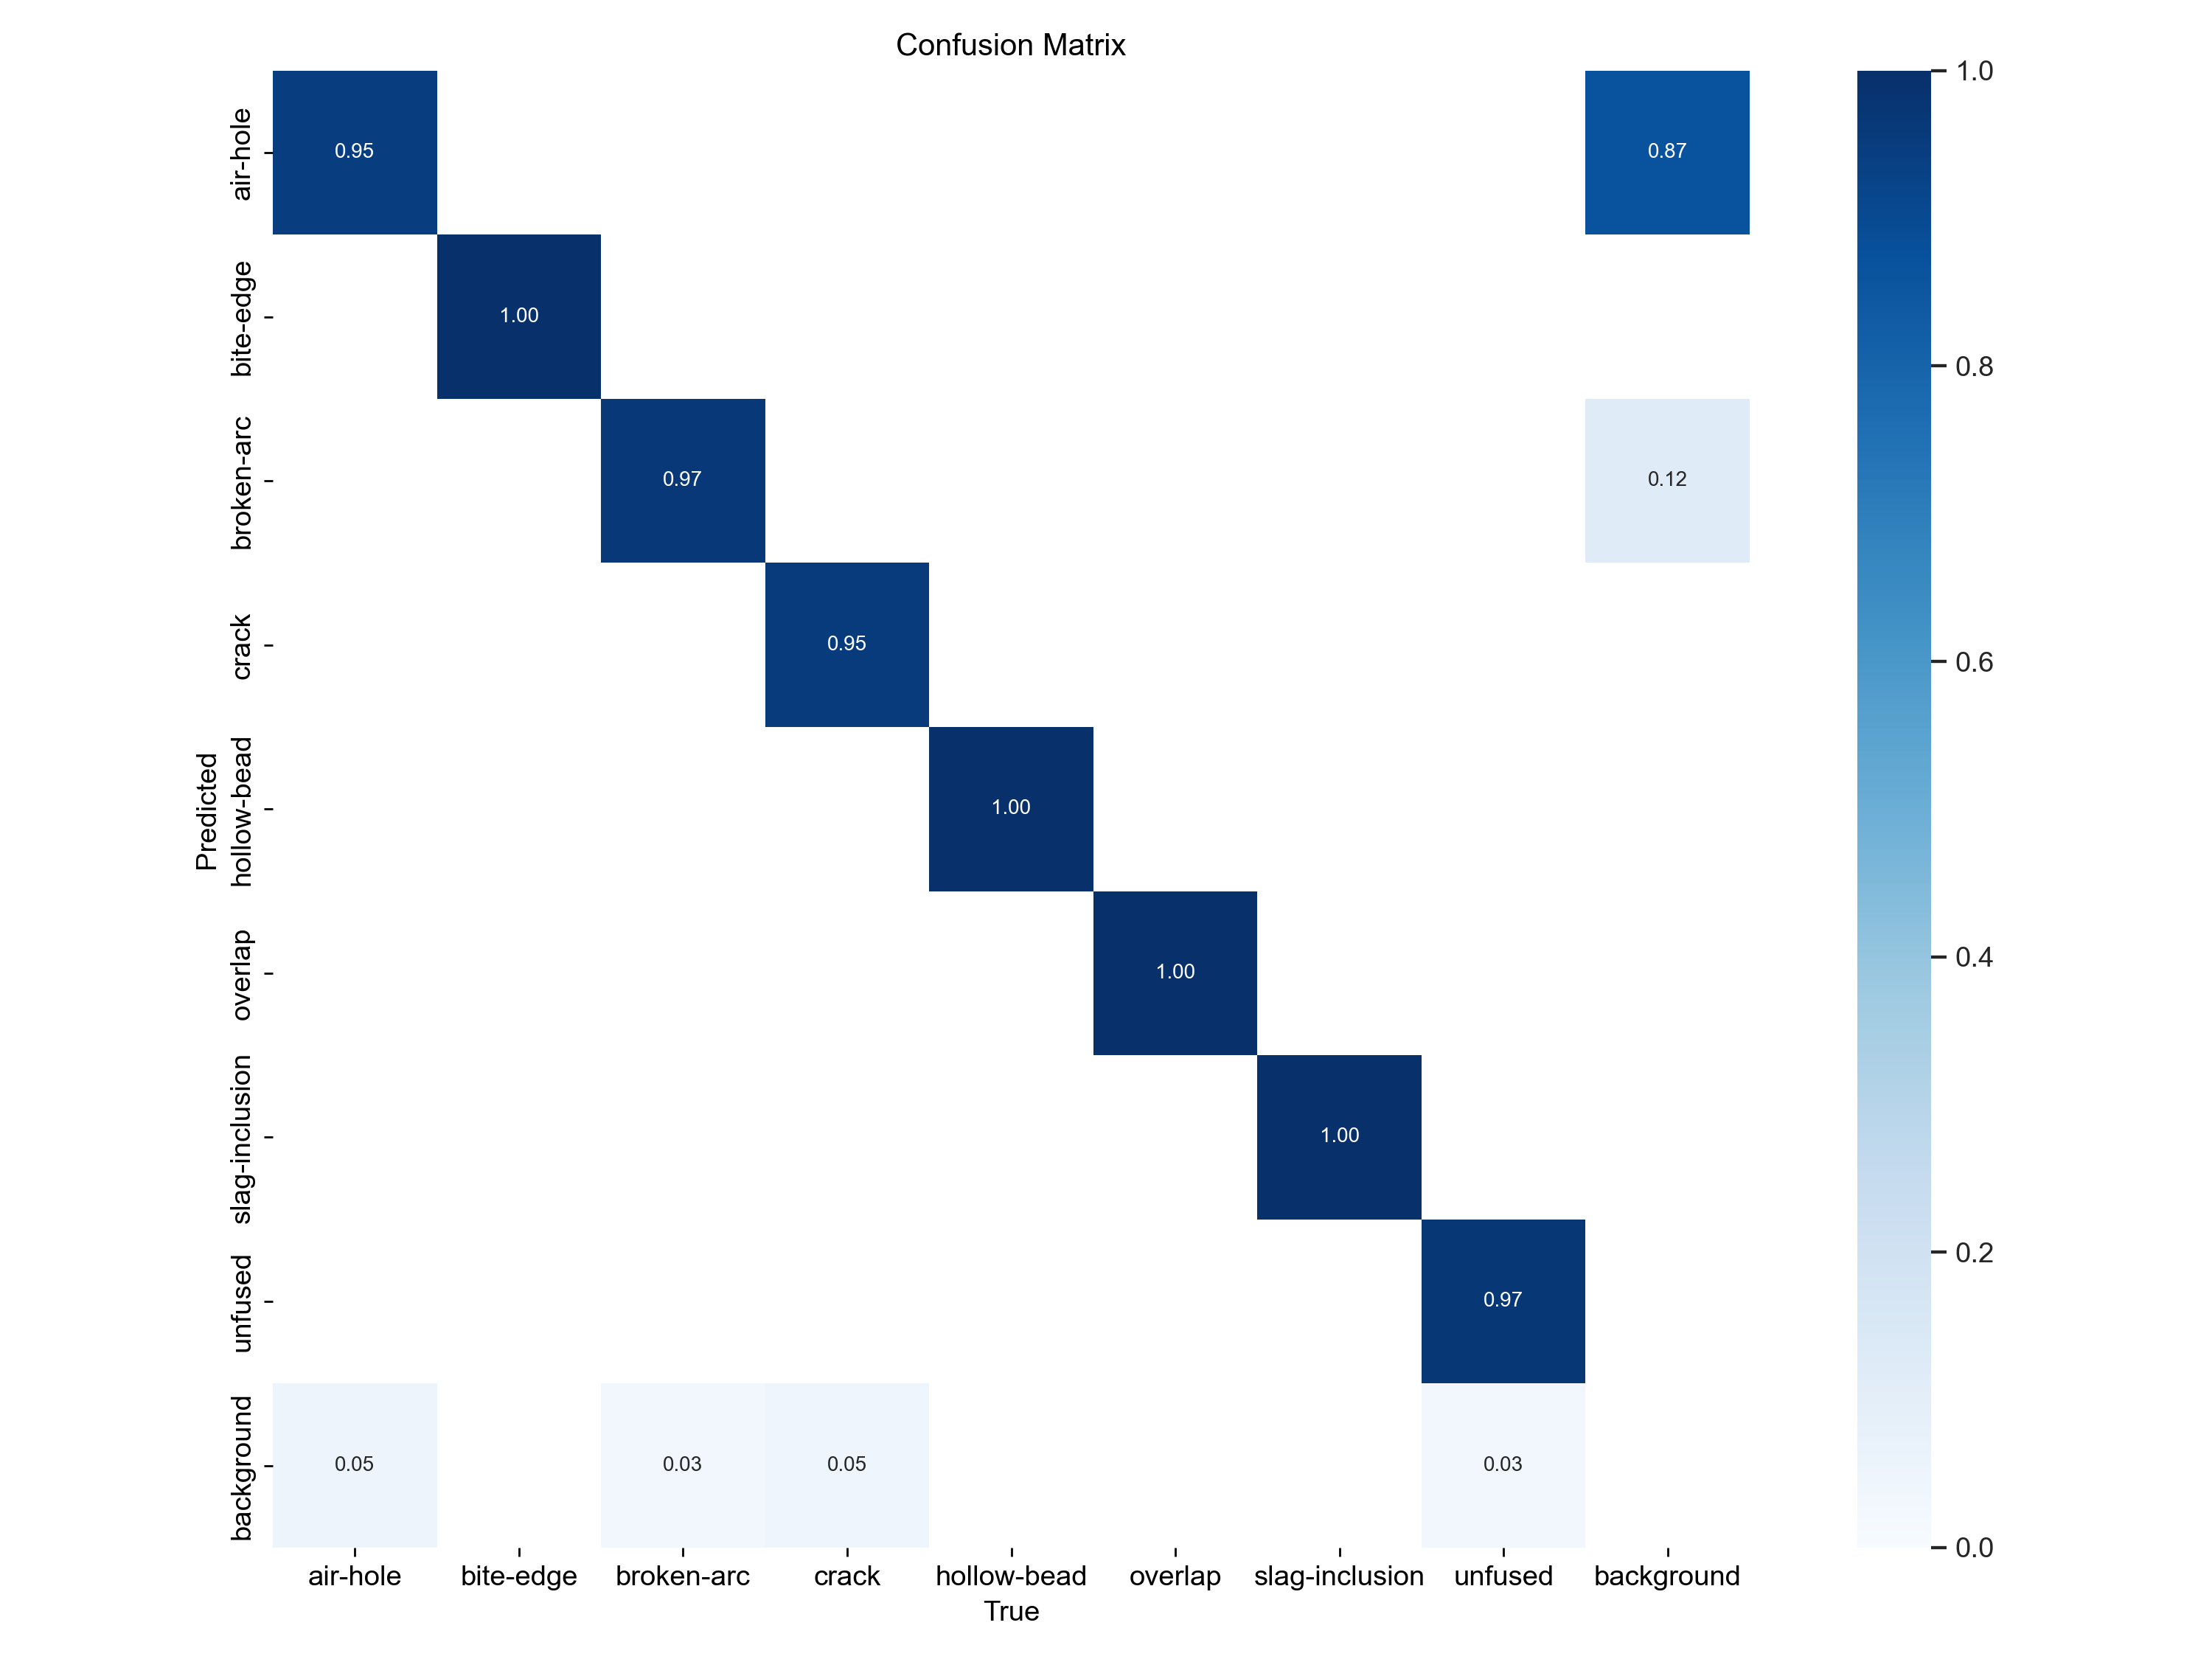

PR_curve.png


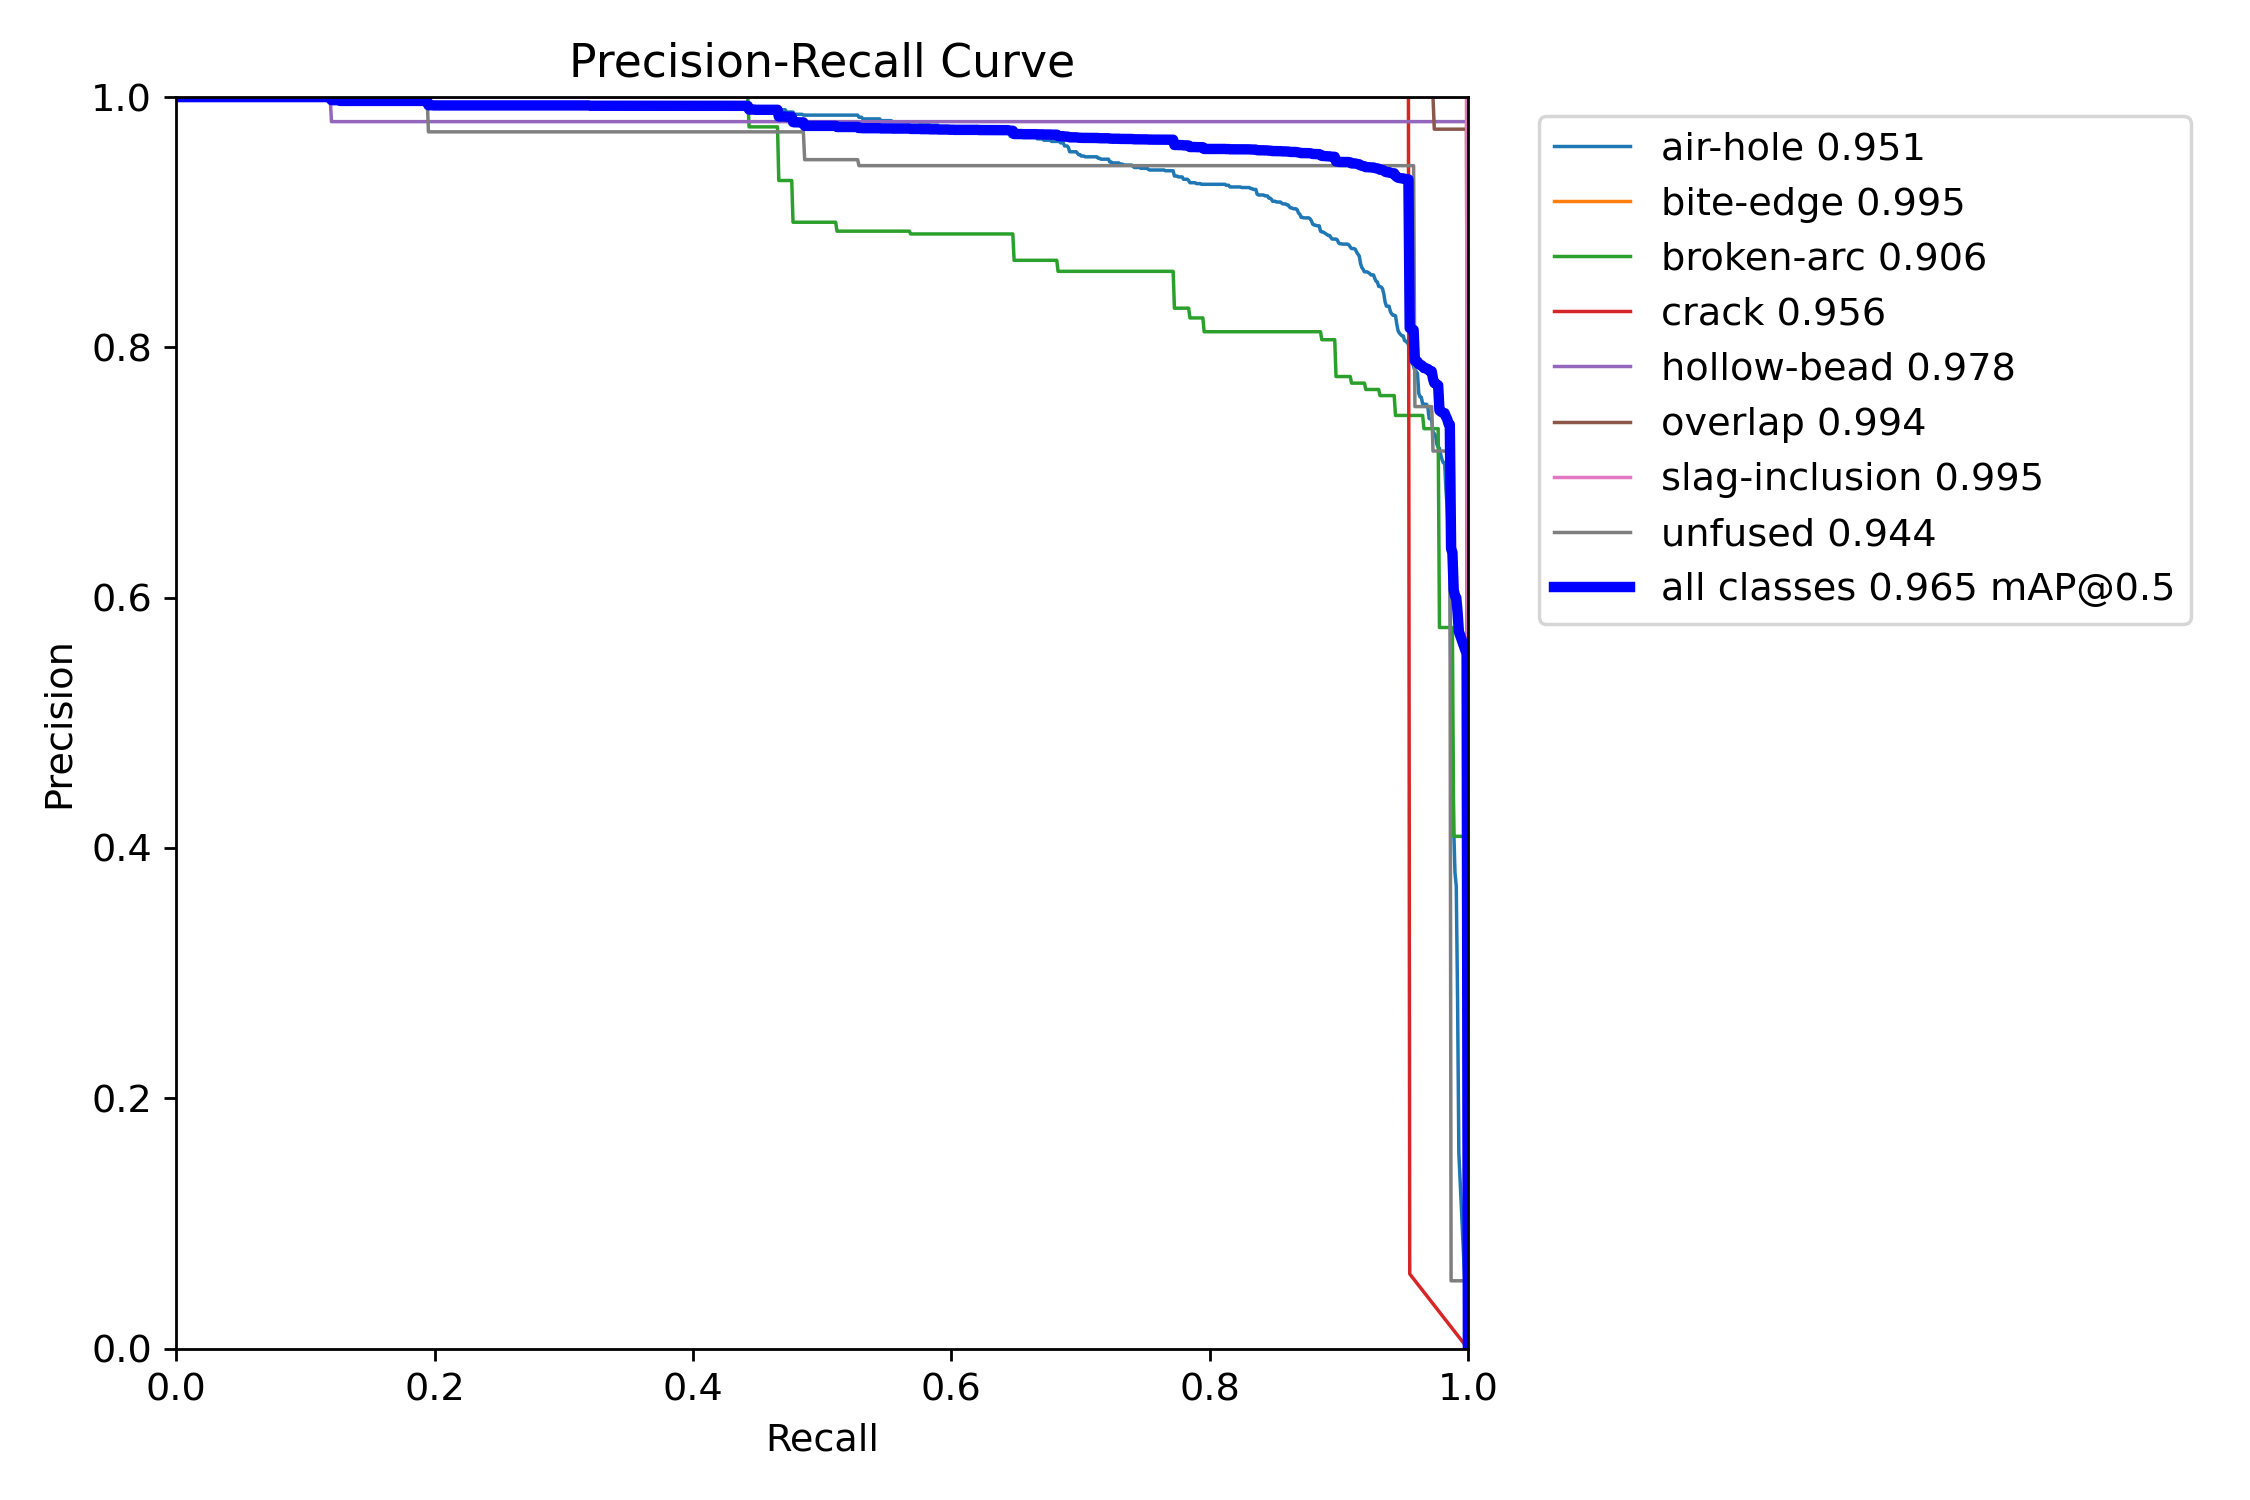

F1_curve.png


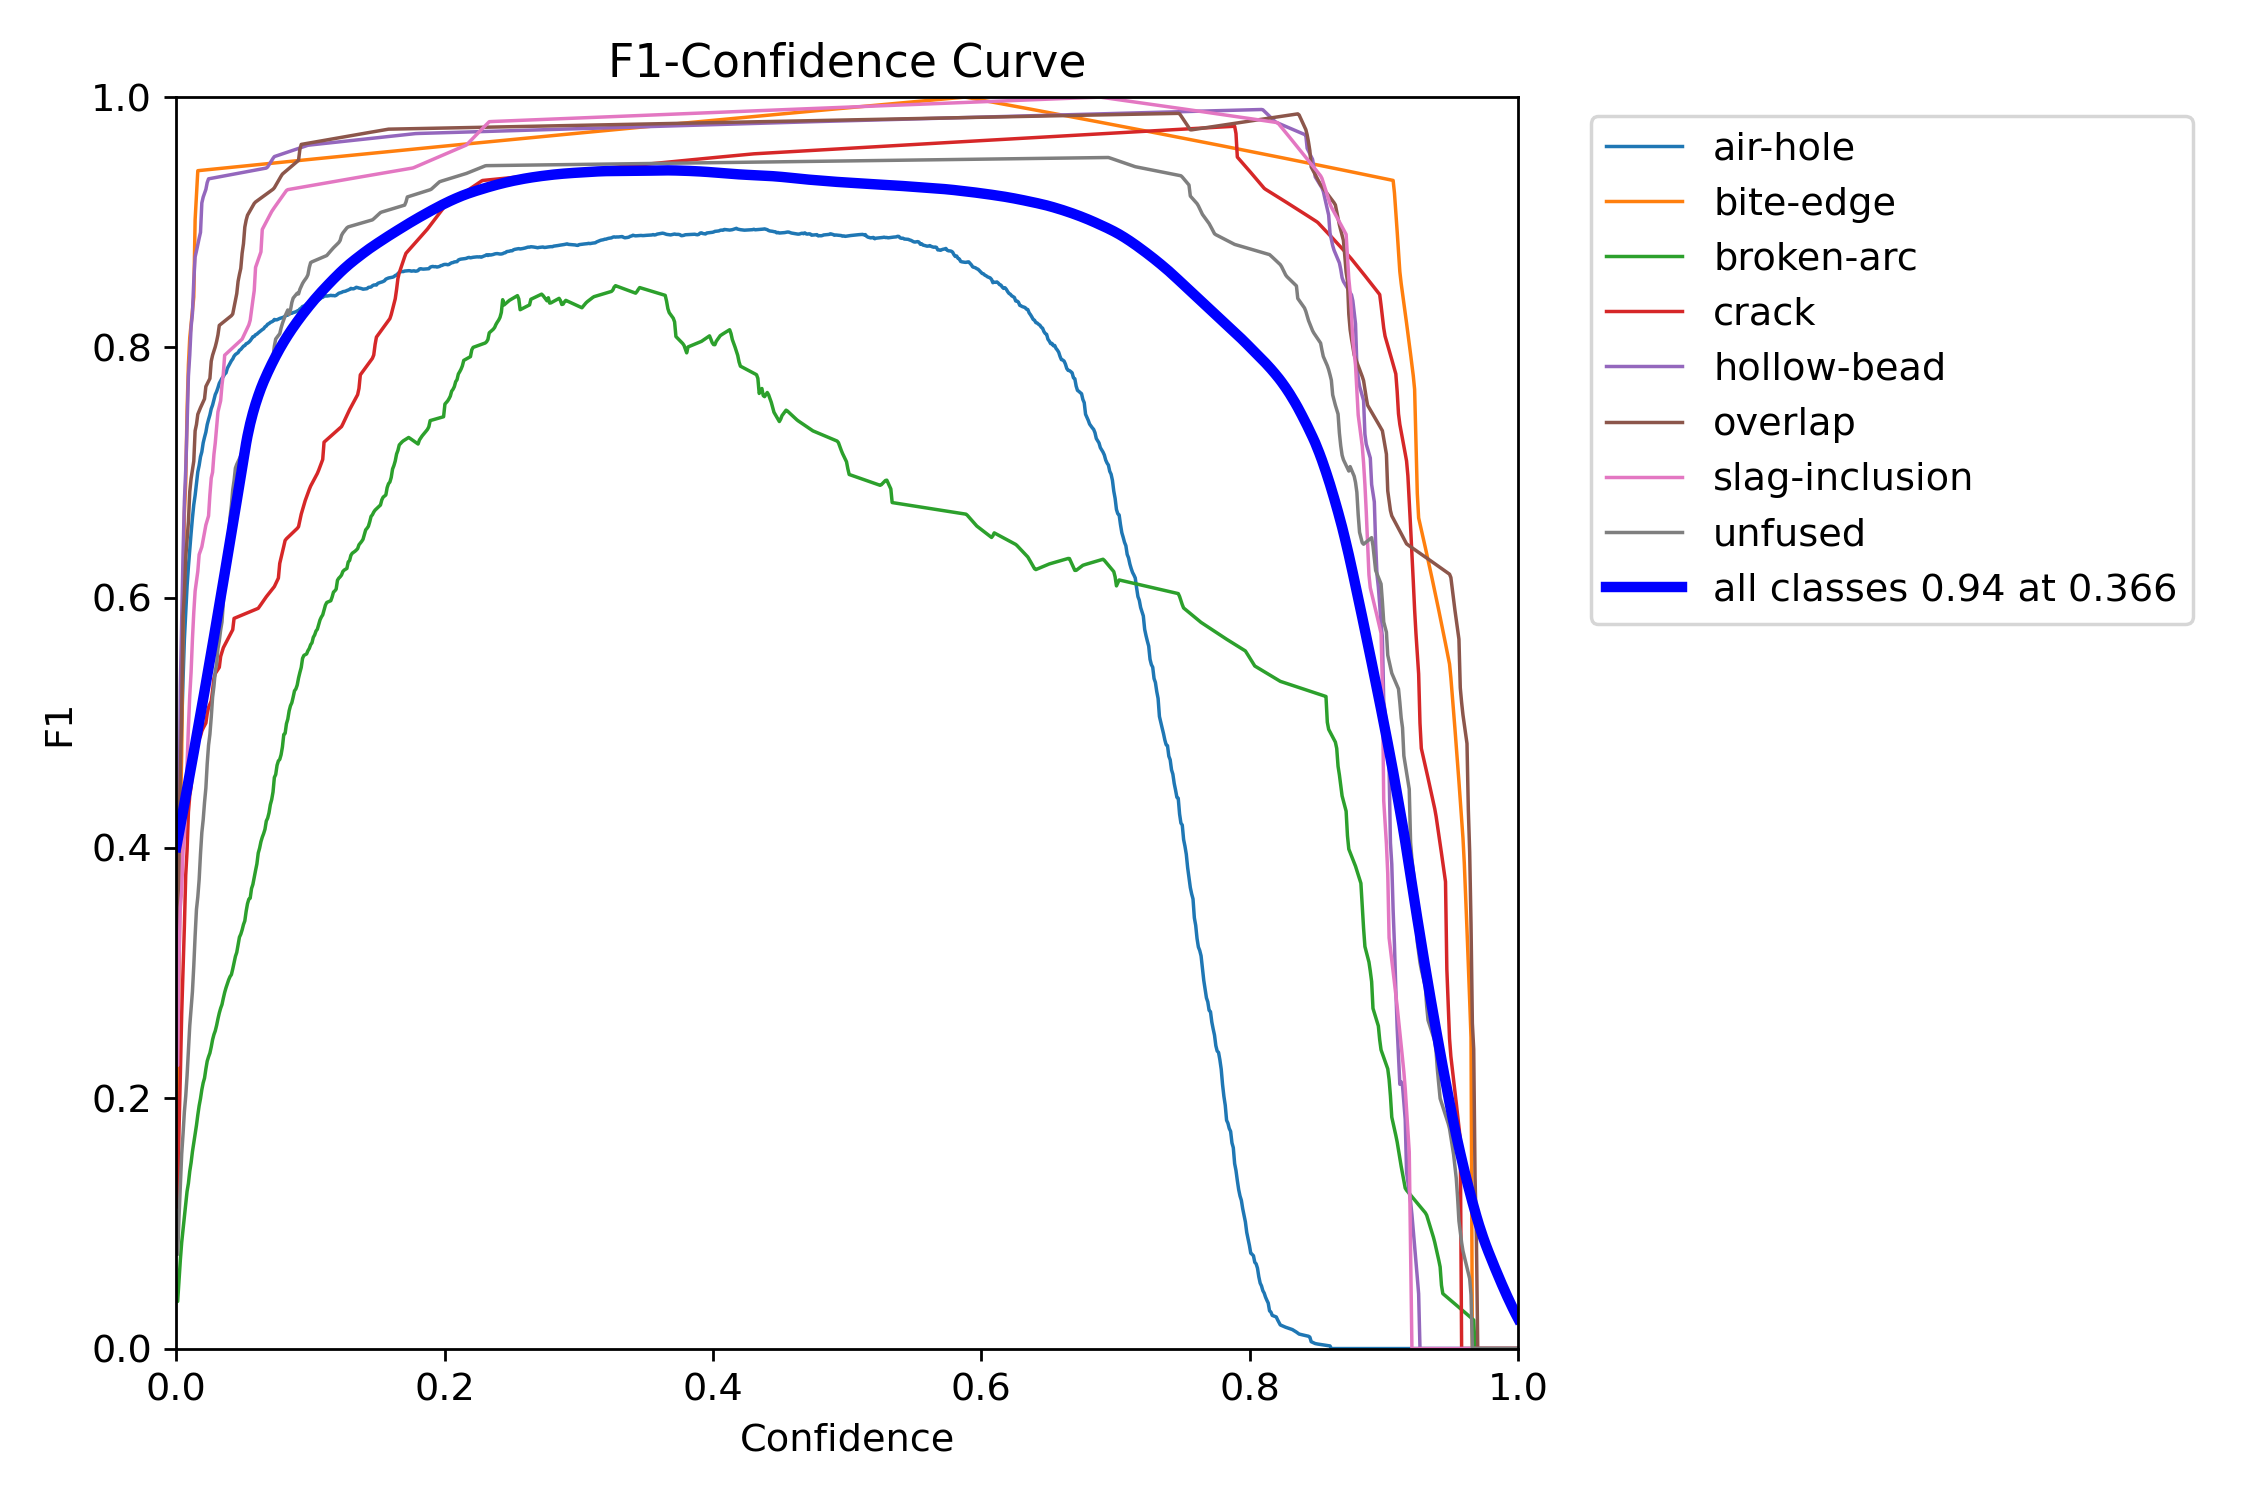

In [ ]:
from IPython.display import display, Image
from pathlib import Path

run = Path("/content/drive/MyDrive/RT_weld_project/runs_weld/v5x_300")

for name in [
    "results.png",
    "confusion_matrix.png",
    "PR_curve.png",
    "F1_curve.png"
]:
    p = run / name
    print(name)
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print("파일 없음")

In [ ]:
!pip install -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 7.7 MB/s eta 0:00:00


YOLOv5 🚀 2026-10-7 Python-3.13.16 torch-2.11.0+cpu CPU



Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


Fusing layers... 
Model summary: 134 layers, 86,220,517 parameters, 0 gradients, 203.9 GFLOPs
Adding AutoShape... 


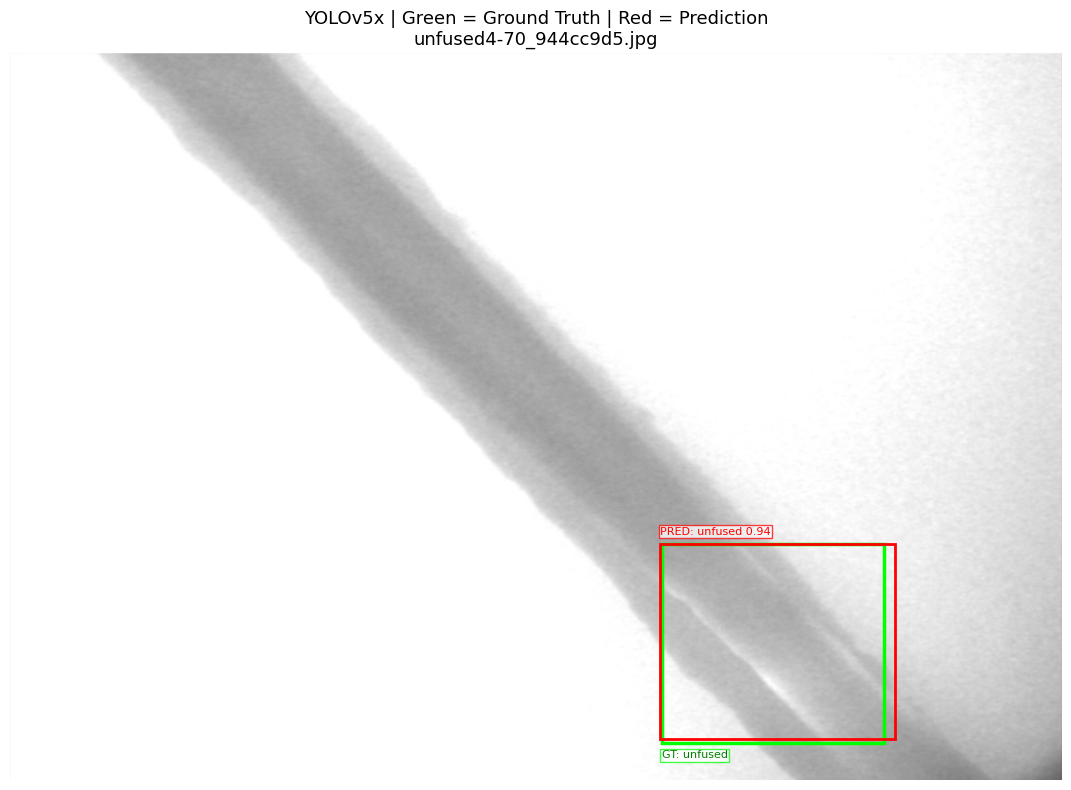

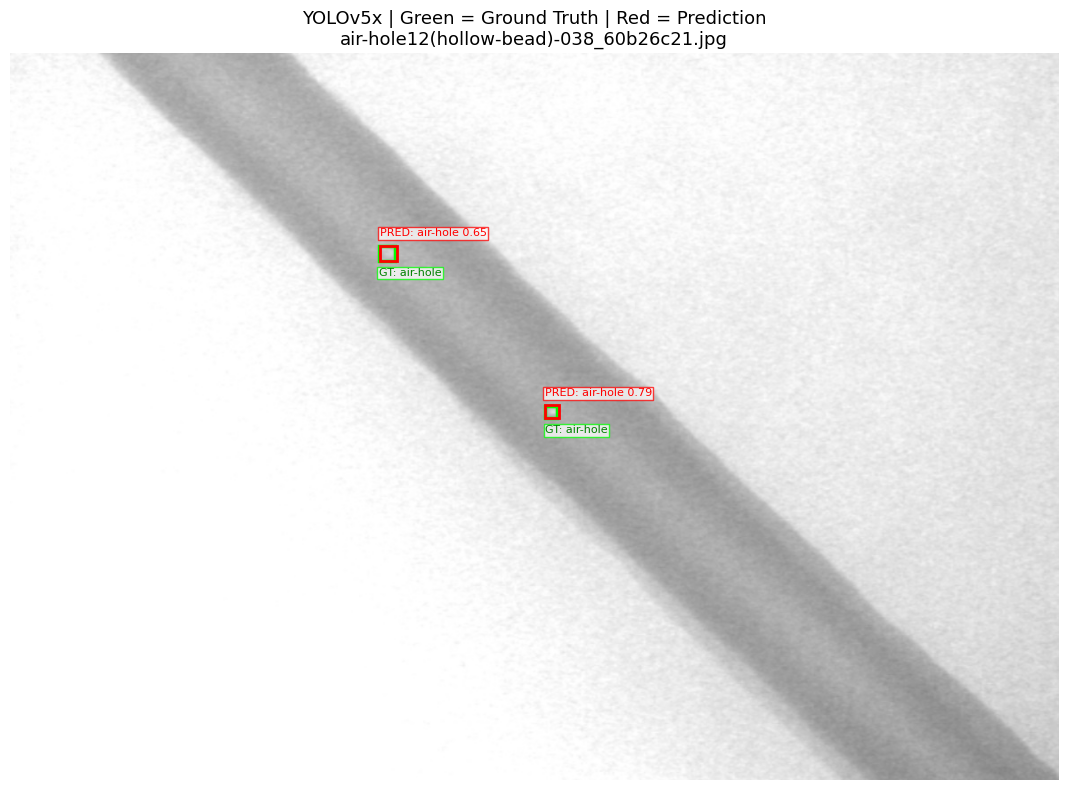

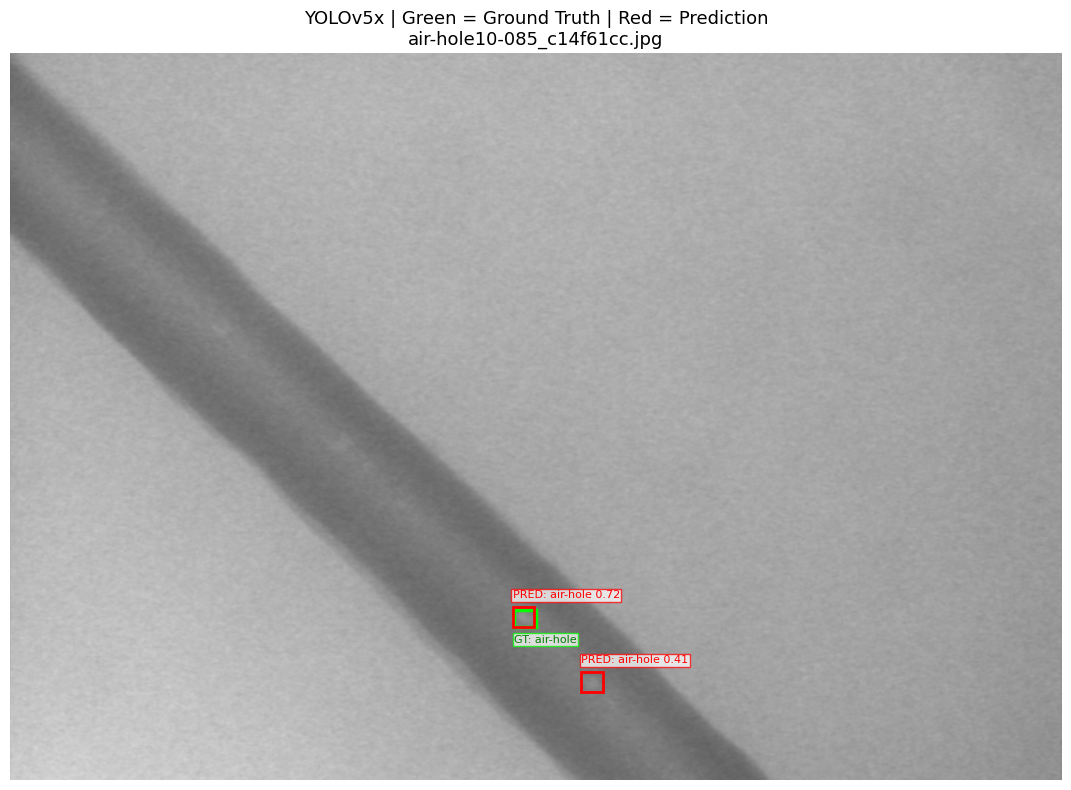

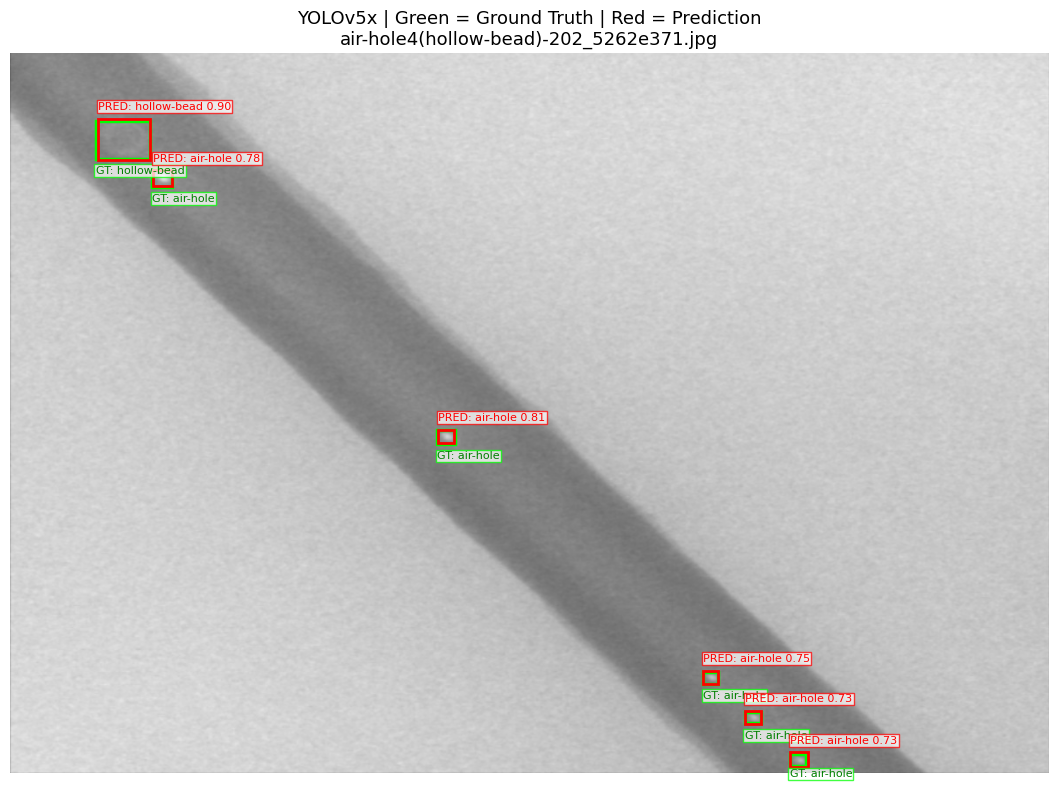

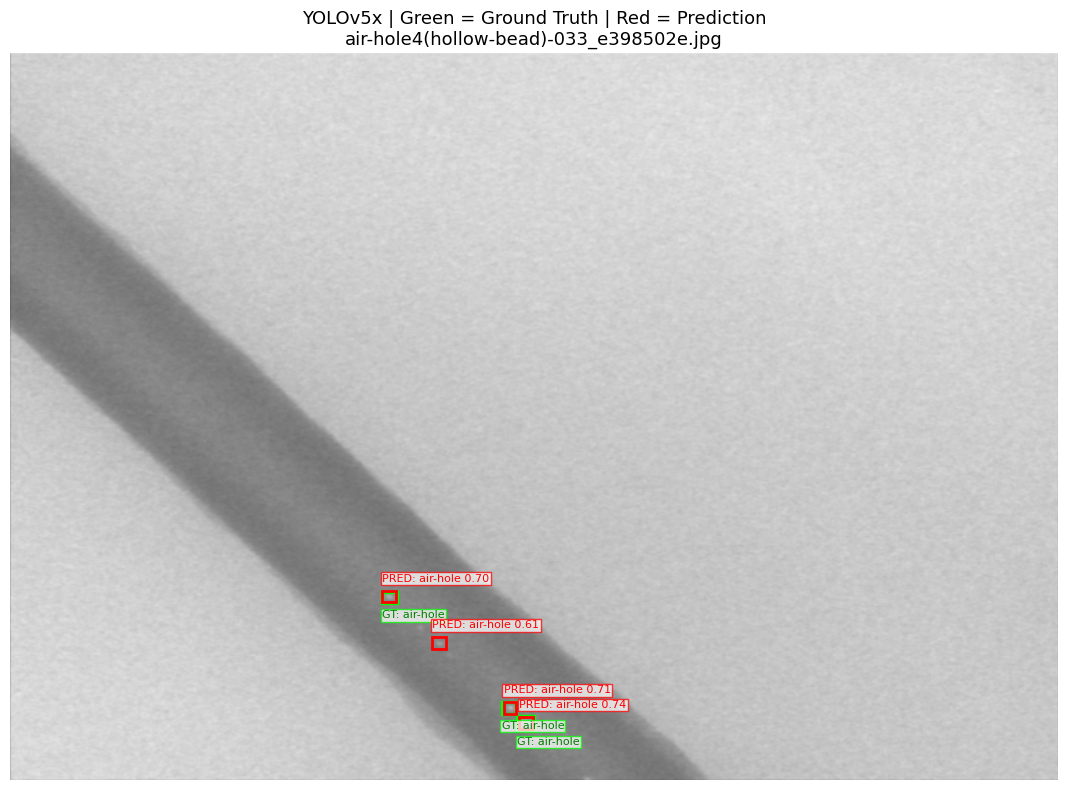

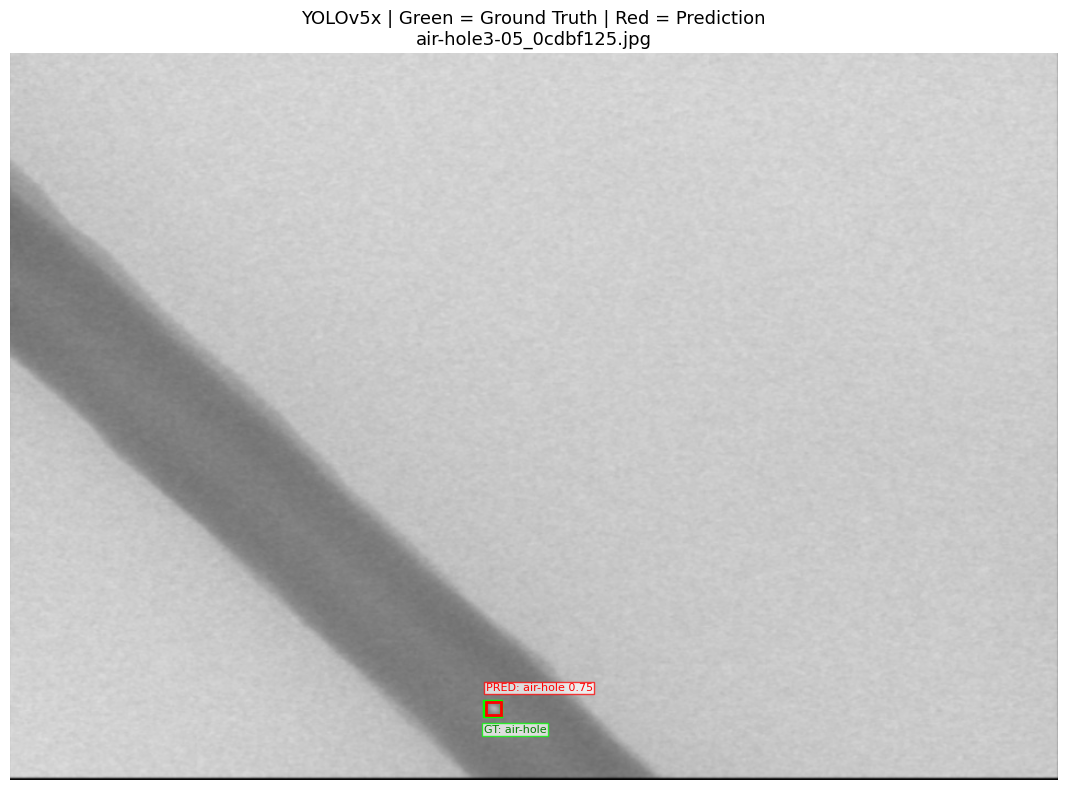

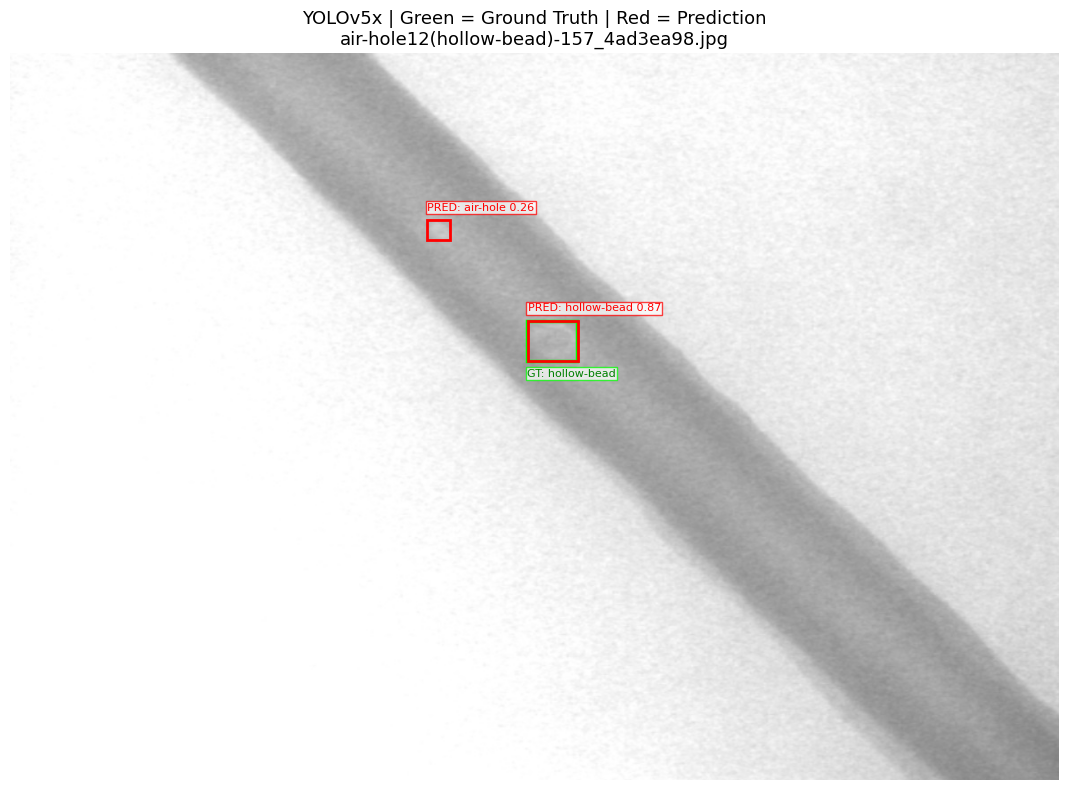

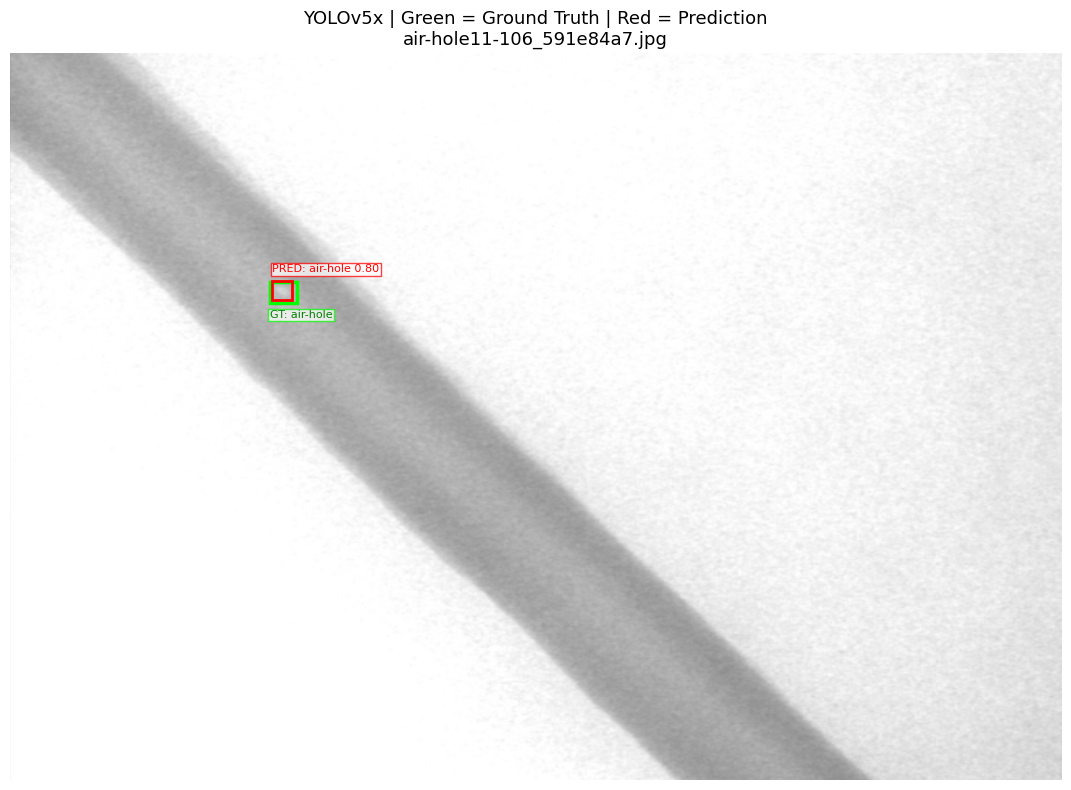

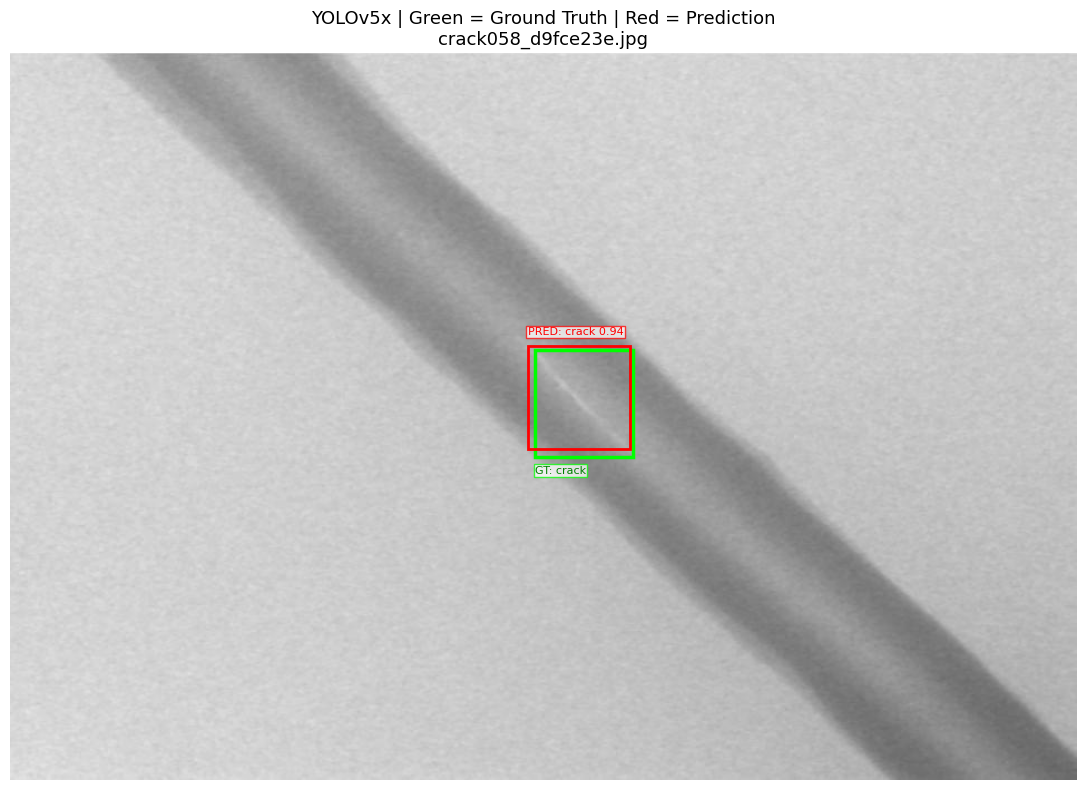

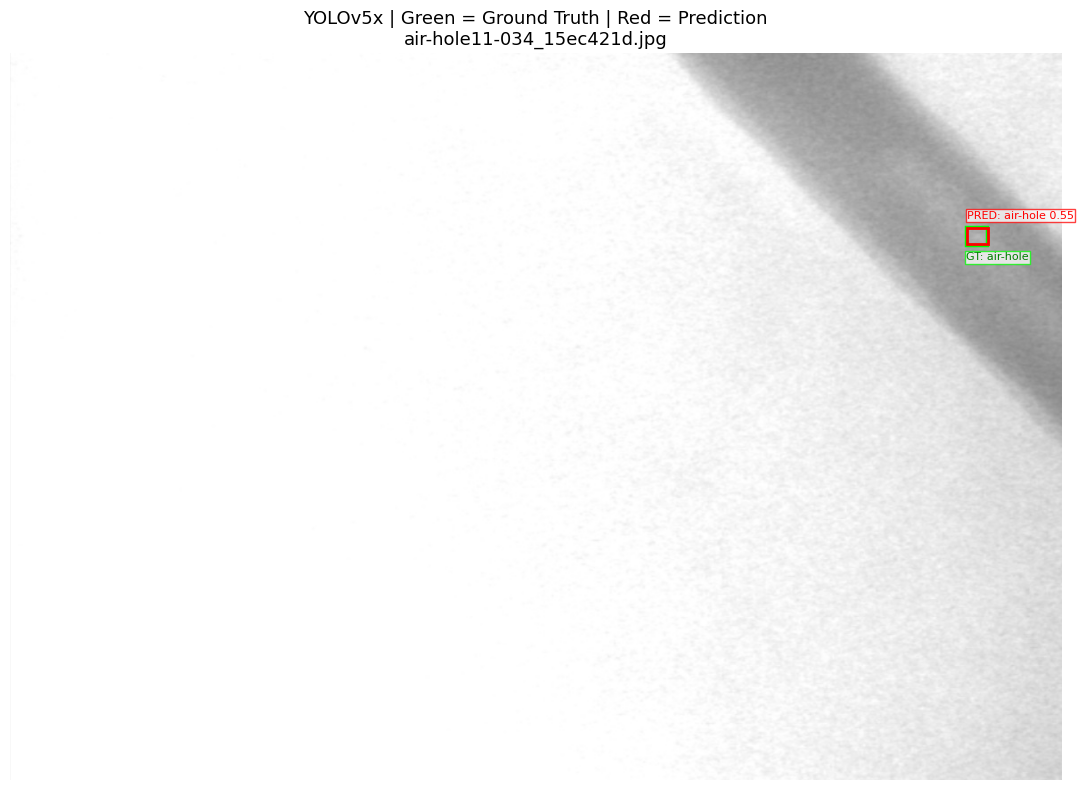

In [ ]:
import torch
from pathlib import Path
from PIL import Image

import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches


model = torch.hub.load(
    "ultralytics/yolov5",
    "custom",
    path="/content/drive/MyDrive/RT_weld_project/runs_weld/v5x_300/weights/best.pt",
    trust_repo=True
)

model.conf = 0.25


val_img_dir = Path(
    "/content/drive/MyDrive/RT_weld_project/weld_yolo/images/val"
)

val_label_dir = Path(
    "/content/drive/MyDrive/RT_weld_project/weld_yolo/labels/val"
)

images = sorted(val_img_dir.glob("*"))

random.seed(42)
sample_images = random.sample(images, 10)

results = model(
    [str(x) for x in sample_images],
    size=640
)


for i, image_path in enumerate(sample_images):

    img = Image.open(image_path).convert("RGB")

    width, height = img.size

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(img)

    # =========================
    # GT = 초록색
    # =========================
    label_path = val_label_dir / f"{image_path.stem}.txt"

    if label_path.exists():

        with open(label_path, "r") as f:
            lines = f.readlines()

        for line in lines:

            cls, xc, yc, w, h = map(float, line.strip().split())
            cls = int(cls)

            x1 = (xc - w / 2) * width
            y1 = (yc - h / 2) * height
            x2 = (xc + w / 2) * width
            y2 = (yc + h / 2) * height

            class_name = model.names[cls]

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2.5,
                edgecolor="lime",
                facecolor="none"
            )

            ax.add_patch(rect)

            gt_y = min(height - 5, y2 + 8)

            ax.text(
                x1,
                gt_y,
                f"GT: {class_name}",
                fontsize=8,
                color="green",
                verticalalignment="top",
                bbox=dict(
                    facecolor="white",
                    edgecolor="lime",
                    alpha=0.75,
                    pad=1
                )
            )

    # =========================
    # PRED = 빨간색
    # =========================
    predictions = results.xyxy[i].cpu().numpy()

    for pred in predictions:

        x1, y1, x2, y2, conf, cls = pred

        class_name = model.names[int(cls)]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        pred_y = max(5, y1 - 8)

        ax.text(
            x1,
            pred_y,
            f"PRED: {class_name} {conf:.2f}",
            fontsize=8,
            color="red",
            verticalalignment="bottom",
            bbox=dict(
                facecolor="white",
                edgecolor="red",
                alpha=0.75,
                pad=1
            )
        )

    ax.set_title(
        f"YOLOv5x | Green = Ground Truth | Red = Prediction\n{image_path.name}",
        fontsize=13
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
import os
import subprocess
import textwrap
import torch

# =========================
# 1. YOLOv5 코드 준비
# =========================
repo = "/content/yolov5_val"

if not os.path.exists(repo):
    subprocess.run(
        ["git", "clone", "-q", "https://github.com/ultralytics/yolov5.git", repo],
        check=True
    )

subprocess.run(
    ["pip", "install", "-q", "-r", f"{repo}/requirements.txt"],
    check=True
)


# =========================
# 2. Drive 데이터셋용 yaml 생성
# =========================
yaml_path = "/content/weld_drive.yaml"

yaml_text = """
path: /content/drive/MyDrive/RT_weld_project/weld_yolo

train: images/train
val: images/val

nc: 8

names:
  0: air-hole
  1: bite-edge
  2: broken-arc
  3: crack
  4: hollow-bead
  5: overlap
  6: slag-inclusion
  7: unfused
"""

with open(yaml_path, "w") as f:
    f.write(textwrap.dedent(yaml_text))


# =========================
# 3. YOLOv5 best.pt
# =========================
best_pt = (
    "/content/drive/MyDrive/RT_weld_project/"
    "runs_weld/v5x_300/weights/best.pt"
)

print("best.pt 존재:", os.path.exists(best_pt))


# =========================
# 4. GPU 있으면 GPU, 없으면 CPU 사용
# =========================
device = "0" if torch.cuda.is_available() else "cpu"

print("사용 device:", device)


# =========================
# 5. Validation 실행
# =========================
subprocess.run(
    [
        "python",
        f"{repo}/val.py",

        "--data", yaml_path,
        "--weights", best_pt,

        "--img", "640",
        "--batch-size", "16",
        "--device", device,

        "--project",
        "/content/drive/MyDrive/RT_weld_project/runs_weld",

        "--name", "v5x_best_reval",
        "--exist-ok"
    ],
    check=True
)

best.pt 존재: True
사용 device: cpu


CompletedProcess(args=['python', '/content/yolov5_val/val.py', '--data', '/content/weld_drive.yaml', '--weights', '/content/drive/MyDrive/RT_weld_project/runs_weld/v5x_300/weights/best.pt', '--img', '640', '--batch-size', '16', '--device', 'cpu', '--project', '/content/drive/MyDrive/RT_weld_project/runs_weld', '--name', 'v5x_best_reval', '--exist-ok'], returncode=0)

In [ ]:
import pandas as pd

csv_path = "/content/drive/MyDrive/RT_weld_project/runs_weld/v5x_300/results.csv"

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

# YOLOv5 best.pt 선택에 사용하는 fitness
# mAP@0.5 10% + mAP@0.5:0.95 90%
df["fitness"] = (
    0.1 * df["metrics/mAP_0.5"] +
    0.9 * df["metrics/mAP_0.5:0.95"]
)

best_idx = df["fitness"].idxmax()
row = df.loc[best_idx]

print("=== YOLOv5x best.pt 기준 성능 ===")
print(f"Epoch          : {int(row['epoch'])}")
print(f"Precision      : {row['metrics/precision']:.5f}")
print(f"Recall         : {row['metrics/recall']:.5f}")
print(f"mAP@0.5        : {row['metrics/mAP_0.5']:.5f}")
print(f"mAP@0.5:0.95   : {row['metrics/mAP_0.5:0.95']:.5f}")
print(f"Fitness        : {row['fitness']:.5f}")

=== YOLOv5x best.pt 기준 성능 ===
Epoch          : 298
Precision      : 0.92460
Recall         : 0.96454
mAP@0.5        : 0.96522
mAP@0.5:0.95   : 0.66852
Fitness        : 0.69819
